In [2]:
# import warnings

# with warnings.catch_warnings():
#     warnings.simplefilter(action="ignore", category=FutureWarning)
import os, math
from pathlib import Path
import scanpy as sc
import numpy as np
import seaborn as sns
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from tqdm import tqdm
from scipy import stats
from scipy.stats import pearsonr, spearmanr
from scipy.sparse import issparse

from scipy.stats import wilcoxon, rankdata
from statsmodels.stats.multitest import multipletests
from itertools import combinations

pd.set_option("display.max_rows", 500)
pd.set_option("display.max_columns", None)

# os.chdir(".././")

In [3]:
obs = pd.read_csv("5.1_3_obs_all_scores_and_bins.csv", index_col=0, engine="python")
obs.rename(columns={"sp_score": "sp", "sid_score": "sid"}, inplace=True)
print(obs.shape)
obs.sample(2)

(1253024, 27)


,GSE_id,GSM_id,Age,Tissue_global,cell_type_final,Age_bin,cell_type,n_expr_genes,sp,RecSID,sid,ds,fridman,cellage,senmayo,sp_centered_median,sid_centered_median,ds_centered_median,sp_is_sen_median_ct,sid_is_sen_median_ct,ds_is_sen_median_ct,sp_is_sen_median_gse,sid_is_sen_median_gse,ds_is_sen_median_gse,sp_is_sen_median_gsm,sid_is_sen_median_gsm,ds_is_sen_median_gsm
H0025_RV_TTGCATTAGTAAAGCT,Heart_Nuclei,H3,53.0,Heart_Nuclei,Mural cell,51.0,Mural cells,827.0,0.786173,SID3,0.186426,-0.198486,0.039002,0.053983,0.021600,0.613580,-0.578407,0.902177,False,False,True,False,False,True,False,False,True
H0035_LA_GTGTTCCGTACCAGAG,Heart_Nuclei,H7,48.0,Heart_Nuclei,Atrial Cardiomyocyte,41.0,Atrial cardiomyocytes,2080.0,0.124492,SID3,0.711376,-0.617262,0.019082,0.040300,0.009944,-0.032663,-0.107026,1.176367,False,False,True,False,False,True,False,False,False


In [4]:
sen_sigs = ["fridman", "senmayo", "cellage"]
methods = ["sp", "ds", "sid"]

In [5]:
cols_to_drop = obs.filter(regex="_is_sen_median_ct$|_is_sen_median_gsm$").columns
obs.drop(columns=cols_to_drop, inplace=True)

In [6]:
"""assign Sc/NSc groups (NSc = ~Sc)"""

for m in methods:
    obs_filt = obs[m]
    obs[f"{m}_sen_group"] = pd.NA
    # valid = obs[m].notna()
    # obs_filt = obs.loc[valid].copy()

    mask_sc = obs[f"{m}_is_sen_median_gse"] == True
    mask_nsc = obs[f"{m}_is_sen_median_gse"] == False
    obs.loc[mask_sc, f"{m}_sen_group"] = "Sc"
    obs.loc[mask_nsc, f"{m}_sen_group"] = "NSc"

In [7]:
obs.columns

Index(['GSE_id', 'GSM_id', 'Age', 'Tissue_global', 'cell_type_final',
       'Age_bin', 'cell_type', 'n_expr_genes', 'sp', 'RecSID', 'sid', 'ds',
       'fridman', 'cellage', 'senmayo', 'sp_centered_median',
       'sid_centered_median', 'ds_centered_median', 'sp_is_sen_median_gse',
       'sid_is_sen_median_gse', 'ds_is_sen_median_gse', 'sp_sen_group',
       'ds_sen_group', 'sid_sen_group'],
      dtype='str')

**AUCell validation**

Дейстивительно ли нашли Sc клетки являются таковыми? Т.е. имеют *более высокий скор для трех независимых универсальных сигнатур сенесцентности*?

Три signatures дают **consistency of independent validation**

- агрегация скоров по донорам (медиана) - тк в данном дизайне независимой биологической единицей является **донор**. Сравнение на уровне отдельных клеток приведет к **псевдорепликации**
- **Wilcoxon signed-rank test**; 
- rank-biserial correlation (**RBC**) for effect size estimation
- 

In [ ]:
# %pip install statannotations

In [90]:
from statannotations.Annotator import Annotator


def plot_senescence_boxplots_with_effect(obs, method, auc_score_col):
    sns.set(style="whitegrid")

    df = obs.copy()
    df = df[df[f"{method}_sen_group"].isin(["NSc", "Sc"])].copy()
    df = df[df[auc_score_col].notna()]

    palette = {
        "NSc": "#FFD700",  # yellow
        "Sc": "#2ca02c",  # green
    }

    for t in sorted(df["Tissue_global"].unique()):
        df_t = df[df["Tissue_global"] == t]

        # общий диапазон Y для всей ткани
        y_min = df_t[auc_score_col].min()
        y_max = df_t[auc_score_col].max()
        pad = 0.05 * (y_max - y_min)
        y_lim = (y_min - pad, y_max + pad)

        ct_list = sorted(df_t["cell_type_final"].unique())

        n_cols = 6
        n_rows = int(np.ceil(len(ct_list) / n_cols))

        fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 5 * n_rows))
        axes = axes.flatten()

        for i, ct in enumerate(ct_list):
            ax = axes[i]
            d_ct = df_t[df_t["cell_type_final"] == ct]

            if d_ct[f"{method}_sen_group"].nunique() < 2:
                ax.set_title(f"{ct} (missing group)")
                ax.axis("off")
                continue

            sns.boxplot(
                data=d_ct,
                x=f"{method}_sen_group",
                y=auc_score_col,
                order=["NSc", "Sc"],
                hue=f"{method}_sen_group",
                palette=palette,
                ax=ax,
                showfliers=False,
                whis=1.5,
                boxprops=dict(alpha=0.5),
            )
            # --- считаем n_donors и n_cells ---
            group_stats = d_ct.groupby(f"{method}_sen_group").agg(
                n_cells=(auc_score_col, "size"), n_donors=("GSM_id", "nunique")
            )
            # гарантируем порядок
            labels = []
            for g in ["NSc", "Sc"]:
                if g in group_stats.index:
                    n_cells = group_stats.loc[g, "n_cells"]
                    n_donors = group_stats.loc[g, "n_donors"]
                    labels.append(f"{g}\nn={n_cells}\ndonors={n_donors}")
                else:
                    labels.append(f"{g}\nn=0")
            # применяем подписи
            # ax.set_xticklabels(labels)

            ticks = ax.get_xticks()
            ax.set_xticks(ticks)
            ax.set_xticklabels(labels)

            ax.set_ylim(y_lim)

            # Mann–Whitney + statannotations
            pairs = [("NSc", "Sc")]

            annotator = Annotator(
                ax,
                pairs,
                data=d_ct,
                x=f"{method}_sen_group",
                y=auc_score_col,
                order=["NSc", "Sc"],
            )

            annotator.configure(
                test="Mann-Whitney",
                text_format="star",
                loc="inside",  # ключевое изменение
                verbose=0,
            )

            annotator.apply_and_annotate()

            # Cliff's delta
            x = d_ct[d_ct[f"{method}_sen_group"] == "Sc"][auc_score_col]
            y = d_ct[d_ct[f"{method}_sen_group"] == "NSc"][auc_score_col]

            ax.set_title(ct)
            ax.set_xlabel("")
            # ax.set_ylabel(auc_score_col)
            ax.set_ylabel(f"{auc_score_col} signature score")

        # выключаем пустые оси
        for j in range(i + 1, len(axes)):
            axes[j].axis("off")

        fig.suptitle(
            f"sen_method = {method}, signature = {auc_score_col}\nTissue: {t}",
            fontsize=16,
        )
        plt.tight_layout()
        plt.show()

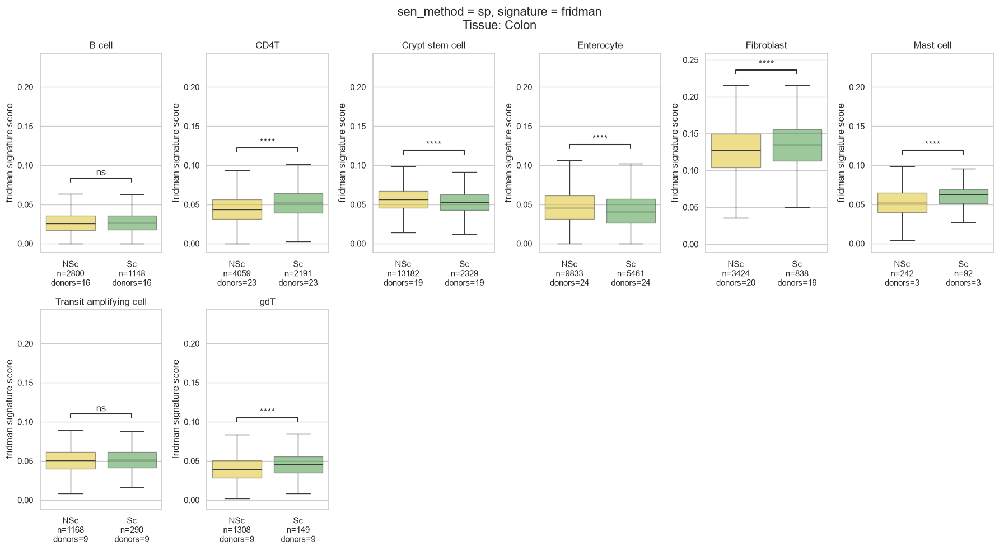

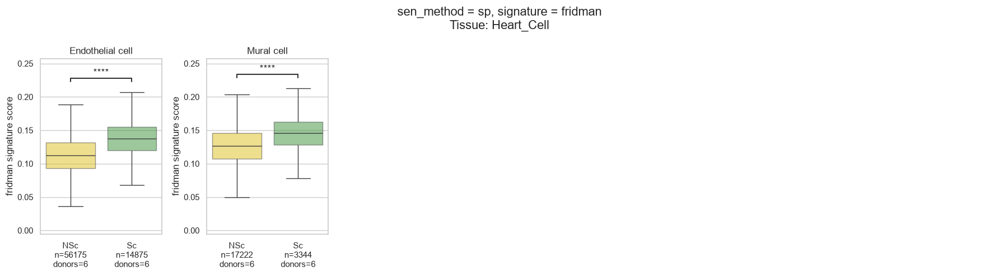

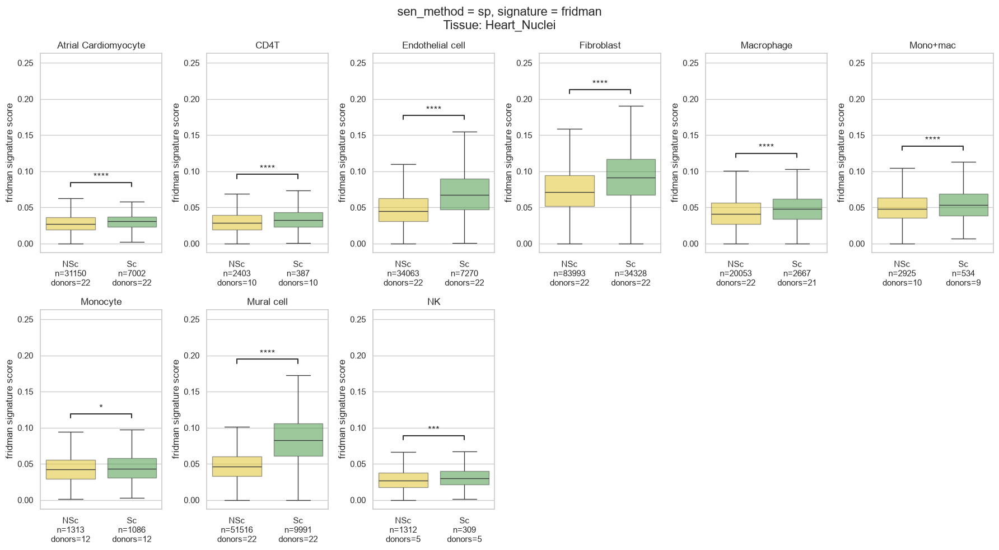

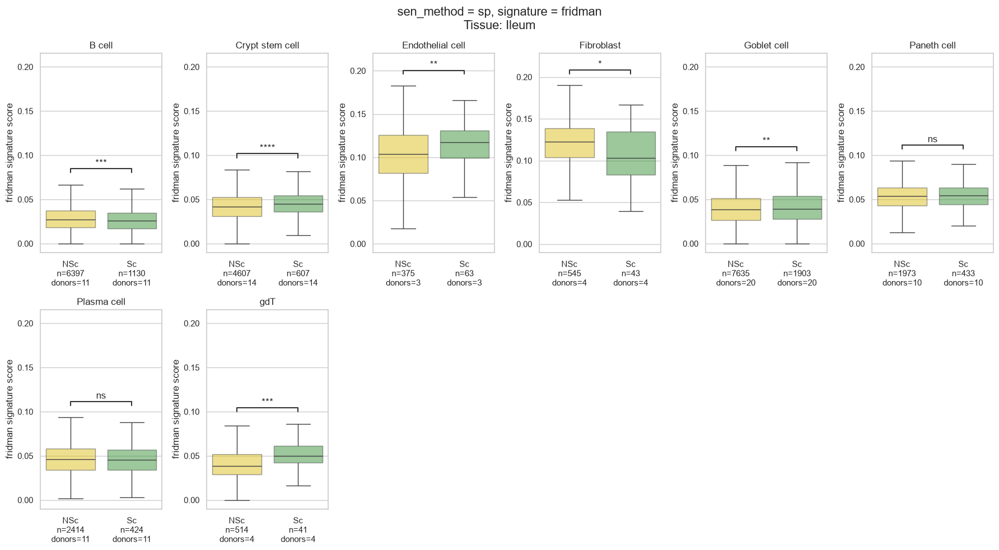

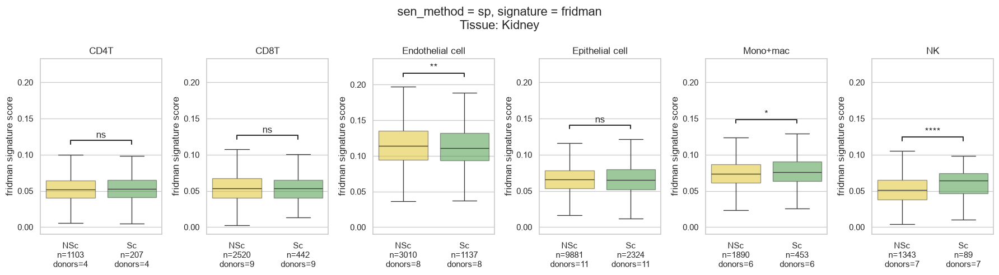

...

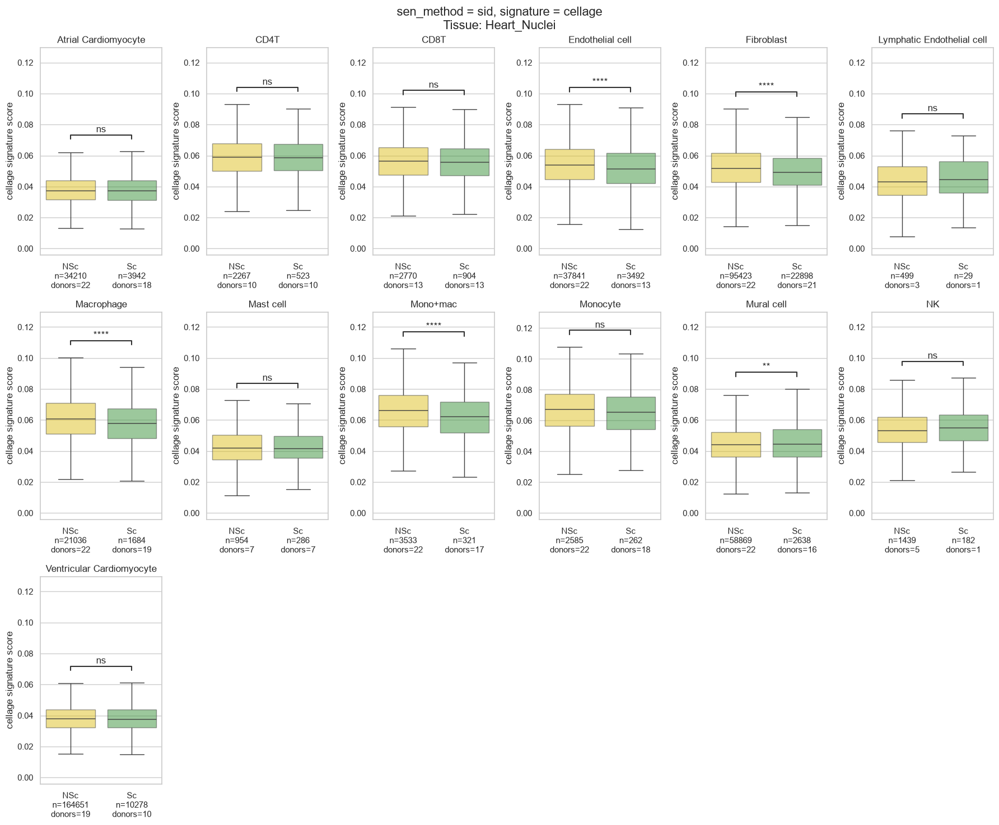

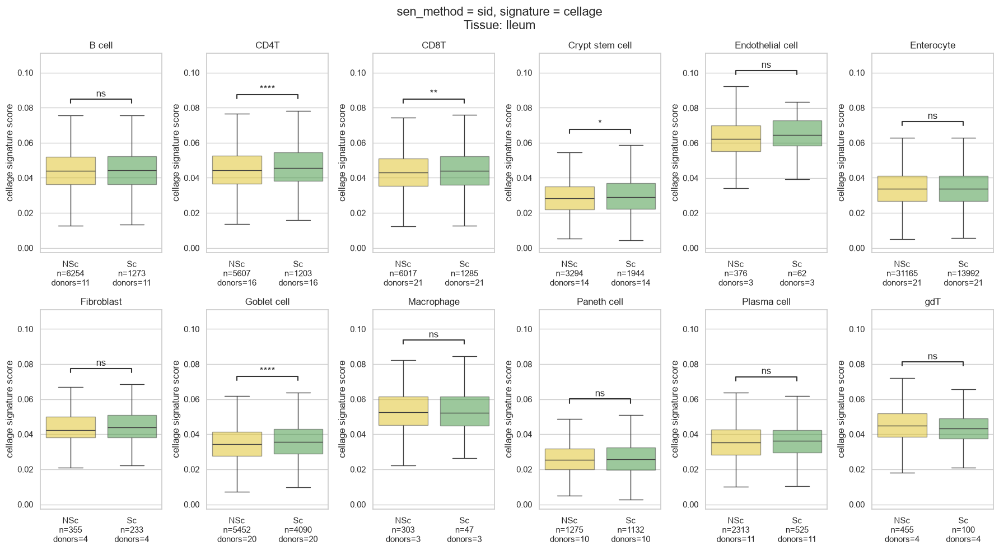

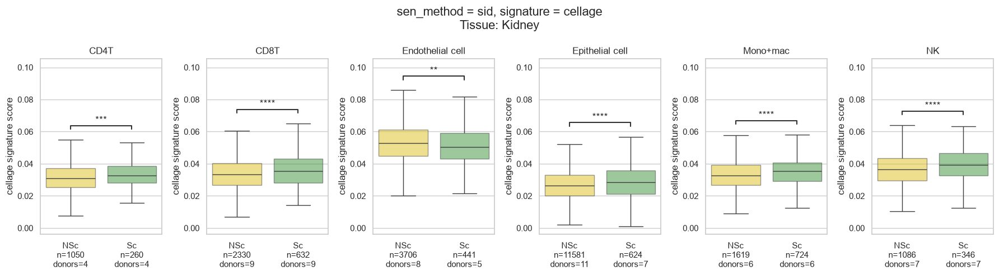

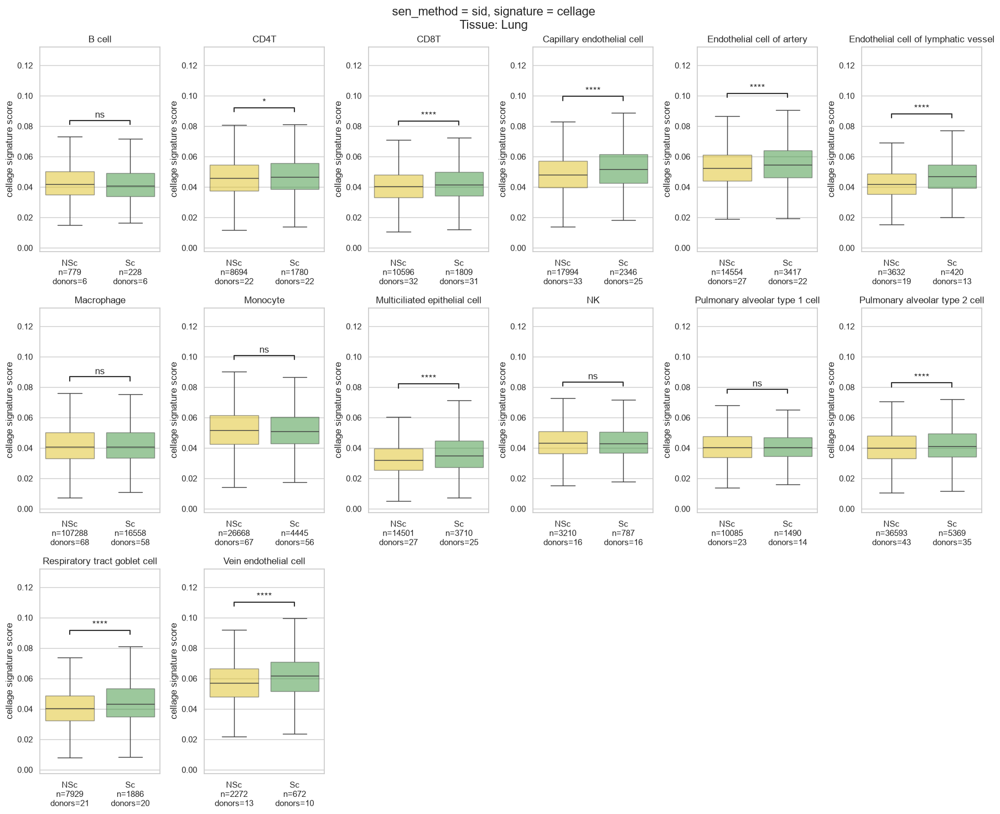

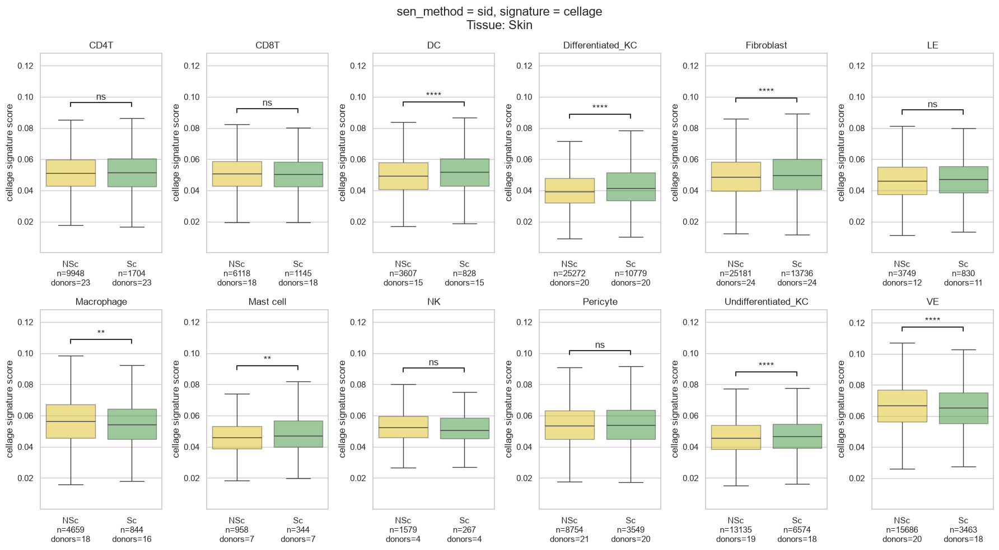

In [91]:
for m in methods:
    for s in sen_sigs:
        plot_senescence_boxplots_with_effect(obs, m, s)

In [9]:
print(obs.fridman.min(), obs.fridman.max())
print(obs.cellage.min(), obs.cellage.max())
print(obs.senmayo.min(), obs.senmayo.max())

0.0 0.330418800762193
0.0011609809021176 0.1260095210573545
0.0 0.2053591397849462


In [8]:
# Missingness and observed ranges in auc scores
auc_info = pd.DataFrame(
    {
        "n_non_missing": obs[sen_sigs].notna().sum(),
        "n_missing": obs[sen_sigs].isna().sum(),
        "min": obs[sen_sigs].min(),
        "max": obs[sen_sigs].max(),
        "median": obs[sen_sigs].median(),
    }
)

auc_info

,n_non_missing,n_missing,min,max,median
fridman,1253024,0,0.000000,0.330419,0.065057
senmayo,1253024,0,0.000000,0.205359,0.043854
cellage,1253024,0,0.001161,0.126010,0.043316


In [9]:
"""2. Aggregate AUCell scores to donor level"""

donor_records = []

for method in methods:
    group_col = f"{method}_sen_group"

    # Keep only cells with a valid Sc/NSc classification
    valid_mask = obs[group_col].notna()

    df = obs.loc[
        valid_mask, ["GSM_id", "Tissue_global", "cell_type", group_col, *sen_sigs]
    ].copy()

    df = df.rename(columns={group_col: "sen_group"})

    for sig in sen_sigs:
        tmp = df[["GSM_id", "Tissue_global", "cell_type", "sen_group", sig]].dropna(
            subset=[sig]
        )

        # Median AUCell score across cells
        # within donor × tissue × cell type × senescence state
        agg = (
            tmp.groupby(
                ["GSM_id", "Tissue_global", "cell_type", "sen_group"], observed=True
            )[sig]
            .median()
            .reset_index()
        )

        agg["method"] = method
        agg["signature"] = sig
        agg["AUCell"] = agg[sig]

        agg = agg.drop(columns=[sig])

        donor_records.append(agg)


donor_auc = pd.concat(donor_records, ignore_index=True)

donor_auc.head()

,GSM_id,Tissue_global,cell_type,sen_group,method,signature,AUCell
0,A61,Heart_Nuclei,Atrial cardiomyocytes,NSc,sp,fridman,0.034610
1,A61,Heart_Nuclei,Atrial cardiomyocytes,Sc,sp,fridman,0.035785
2,A61,Heart_Nuclei,CD4 T cells,NSc,sp,fridman,0.028515
3,A61,Heart_Nuclei,CD4 T cells,Sc,sp,fridman,0.034528
4,A61,Heart_Nuclei,Endothelial cells,NSc,sp,fridman,0.047326


In [10]:
"""3. Create paired donor-level Sc vs NSc data"""

paired_records = []

for keys, group in donor_auc.groupby(
    ["method", "signature", "Tissue_global", "cell_type", "GSM_id"], observed=True
):
    method, signature, tissue, cell_type, donor = keys

    sc = group.loc[group["sen_group"] == "Sc", "AUCell"]

    nsc = group.loc[group["sen_group"] == "NSc", "AUCell"]

    # Keep only donors for which both Sc and NSc are available
    if len(sc) == 1 and len(nsc) == 1:
        paired_records.append(
            {
                "method": method,
                "signature": signature,
                "Tissue_global": tissue,
                "cell_type": cell_type,
                "GSM_id": donor,
                "AUCell_Sc": sc.iloc[0],
                "AUCell_NSc": nsc.iloc[0],
                "delta_AUCell": sc.iloc[0] - nsc.iloc[0],
            }
        )


paired_auc = pd.DataFrame(paired_records)

paired_auc.head()

# теперь каждая строка — donor-level paired observation

,method,signature,Tissue_global,cell_type,GSM_id,AUCell_Sc,AUCell_NSc,delta_AUCell
0,ds,cellage,Colon,B cells,GSM6614348,0.031701,0.037506,-0.005805
1,ds,cellage,Colon,B cells,GSM6614350,0.043108,0.043418,-0.000309
2,ds,cellage,Colon,B cells,GSM7307102,0.033760,0.035108,-0.001349
3,ds,cellage,Colon,B cells,GSM7307103,0.033952,0.035113,-0.001161
4,ds,cellage,Colon,B cells,GSM7307104,0.039316,0.037047,0.002269


сравниваем три signatures между собой через:

RBC, а не через ΔAUCell.

ΔAUCell используем:
- для интерпретации внутри конкретной signature;
- для дополнительной визуализации;
- но не для ранжирования Fridman vs CellAge vs SenMayo.

RBC используем:
- для сравнения sp vs sid vs ds;
- для сравнения Fridman vs CellAge vs SenMayo;
- для общего ranking методов;
- для heatmap.

статистически это прозрачнее, чем вводить дополнительную z-нормализацию.

In [11]:
"""def Rank-biserial correlation """


def rank_biserial_from_differences(differences):
    """
    Rank-biserial correlation for paired data.

    Positive values indicate that Sc tends to have
    higher values than NSc.
    """

    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]

    # Remove zero differences
    differences = differences[differences != 0]

    if len(differences) == 0:
        return np.nan

    abs_diff = np.abs(differences)

    # Average ranks for ties
    ranks = rankdata(abs_diff, method="average")

    positive_rank_sum = ranks[differences > 0].sum()
    negative_rank_sum = ranks[differences < 0].sum()

    denominator = positive_rank_sum + negative_rank_sum

    if denominator == 0:
        return np.nan

    return (positive_rank_sum - negative_rank_sum) / denominator

In [12]:
"""def Bootstrap 95% CI for rank-biserial correlation"""


def bootstrap_rbc_ci(differences, n_boot=10_000, random_state=42):
    """
    Percentile bootstrap 95% CI for rank-biserial correlation.
    Resampling is performed at the donor level.
    """
    differences = np.asarray(differences, dtype=float)
    differences = differences[np.isfinite(differences)]

    n = len(differences)

    if n < 2:
        return np.nan, np.nan

    rng = np.random.default_rng(random_state)

    boot_values = []

    for _ in range(n_boot):
        sample = rng.choice(differences, size=n, replace=True)

        rbc = rank_biserial_from_differences(sample)

        if np.isfinite(rbc):
            boot_values.append(rbc)

    if len(boot_values) == 0:
        return np.nan, np.nan

    ci_low, ci_high = np.percentile(boot_values, [2.5, 97.5])

    return ci_low, ci_high

In [13]:
"""4. Основной статистический анализ"""

results = []

analysis_groups = ["method", "signature", "Tissue_global", "cell_type"]

for keys, group in tqdm(paired_auc.groupby(analysis_groups, observed=True)):
    method, signature, tissue, cell_type = keys

    differences = group["delta_AUCell"].to_numpy()

    n = len(differences)

    # Wilcoxon signed-rank test
    if np.all(differences == 0):
        p_value = 1.0
        statistic = 0.0

    else:
        test = wilcoxon(
            differences, alternative="two-sided", zero_method="wilcox", method="auto"
        )

        statistic = test.statistic
        p_value = test.pvalue

    # Effect size
    rbc = rank_biserial_from_differences(differences)

    # Bootstrap CI
    ci_low, ci_high = bootstrap_rbc_ci(differences, n_boot=1000)

    # Directional consistency
    fraction_positive = np.mean(differences > 0)

    # Median delta
    median_delta = np.median(differences)

    results.append(
        {
            "method": method,
            "signature": signature,
            "Tissue_global": tissue,
            "cell_type": cell_type,
            "n_donors": n,
            "median_AUCell_delta": median_delta,
            "fraction_positive": fraction_positive,
            "wilcoxon_statistic": statistic,
            "p_value": p_value,
            "rank_biserial_r": rbc,
            "rbc_ci_low": ci_low,
            "rbc_ci_high": ci_high,
        }
    )

results_df = pd.DataFrame(results)

results_df.head()

  0%|          | 0/567 [00:00<?, ?it/s]

100%|██████████| 567/567 [00:45<00:00, 12.34it/s]


,method,signature,Tissue_global,cell_type,n_donors,median_AUCell_delta,fraction_positive,wilcoxon_statistic,p_value,rank_biserial_r,rbc_ci_low,rbc_ci_high
0,ds,cellage,Colon,B cells,16,-0.001133,0.250000,41.0,0.175354,-0.397059,-0.955882,0.147059
1,ds,cellage,Colon,CD4 T cells,23,0.001100,0.739130,62.0,0.019557,0.550725,0.144746,0.884058
2,ds,cellage,Colon,CD8 T cells,21,0.000279,0.571429,105.0,0.733470,-0.090909,-0.558442,0.480952
3,ds,cellage,Colon,Crypt stem cells,19,0.002084,0.947368,1.0,0.000008,0.989474,0.936842,1.000000
4,ds,cellage,Colon,Enterocytes,24,0.004994,0.958333,13.0,0.000010,0.913333,0.700000,1.000000


In [14]:
"""FDR correction within method × signature"""

results_df["FDR"] = np.nan

for (method, signature), idx in results_df.groupby(
    ["method", "signature"], observed=True
).groups.items():
    pvals = results_df.loc[idx, "p_value"]

    valid = pvals.notna()

    if valid.sum() == 0:
        continue

    _, pvals_fdr, _, _ = multipletests(pvals[valid], method="fdr_bh")

    valid_idx = pvals[valid].index

    results_df.loc[valid_idx, "FDR"] = pvals_fdr

In [15]:
def significance_label(fdr):
    if pd.isna(fdr):
        return ""
    elif fdr < 0.001:
        return "∗∗∗"
    elif fdr < 0.01:
        return "∗∗"
    elif fdr < 0.05:
        return "∗"
    else:
        return ""


results_df["significance"] = results_df["FDR"].apply(significance_label)

In [16]:
results_df = results_df[
    [
        "method",
        "signature",
        "Tissue_global",
        "cell_type",
        "n_donors",
        "median_AUCell_delta",
        "fraction_positive",
        "wilcoxon_statistic",
        "p_value",
        "FDR",
        "rank_biserial_r",
        "rbc_ci_low",
        "rbc_ci_high",
        "significance",
    ]
].sort_values(["method", "signature", "Tissue_global", "cell_type"])

results_df.head()

,method,signature,Tissue_global,cell_type,n_donors,median_AUCell_delta,fraction_positive,wilcoxon_statistic,p_value,FDR,rank_biserial_r,rbc_ci_low,rbc_ci_high,significance
0,ds,cellage,Colon,B cells,16,-0.001133,0.250000,41.0,0.175354,0.257435,-0.397059,-0.955882,0.147059,
1,ds,cellage,Colon,CD4 T cells,23,0.001100,0.739130,62.0,0.019557,0.048195,0.550725,0.144746,0.884058,∗
2,ds,cellage,Colon,CD8 T cells,21,0.000279,0.571429,105.0,0.733470,0.843490,-0.090909,-0.558442,0.480952,
3,ds,cellage,Colon,Crypt stem cells,19,0.002084,0.947368,1.0,0.000008,0.000053,0.989474,0.936842,1.000000,∗∗∗
4,ds,cellage,Colon,Enterocytes,24,0.004994,0.958333,13.0,0.000010,0.000066,0.913333,0.700000,1.000000,∗∗∗


In [17]:
# Overall method performance

method_summary = (
    results_df.groupby(["method", "signature"], observed=True)
    .agg(
        median_RBC=("rank_biserial_r", "median"),
        mean_RBC=("rank_biserial_r", "mean"),
        median_delta=("median_AUCell_delta", "median"),
        median_fraction_positive=("fraction_positive", "median"),
        n_groups=("rank_biserial_r", "count"),
        n_significant=("FDR", lambda x: (x < 0.05).sum()),
    )
    .reset_index()
)

method_summary

,method,signature,median_RBC,mean_RBC,median_delta,median_fraction_positive,n_groups,n_significant
0,ds,cellage,0.696970,0.520753,0.001930,0.772727,69,29
1,ds,fridman,0.544974,0.398276,0.003007,0.695652,69,27
2,ds,senmayo,0.685714,0.463707,0.003226,0.767442,69,33
3,sid,cellage,0.523810,0.418539,0.000747,0.673333,72,15
4,sid,fridman,0.023377,0.043317,0.000056,0.500000,72,7
5,sid,senmayo,0.219151,0.213105,0.000544,0.617216,72,9
6,sp,cellage,0.341054,0.344160,0.001041,0.666667,48,15
7,sp,fridman,0.685994,0.442492,0.002588,0.753788,48,20
8,sp,senmayo,0.717172,0.475997,0.003200,0.788889,48,21


### viz

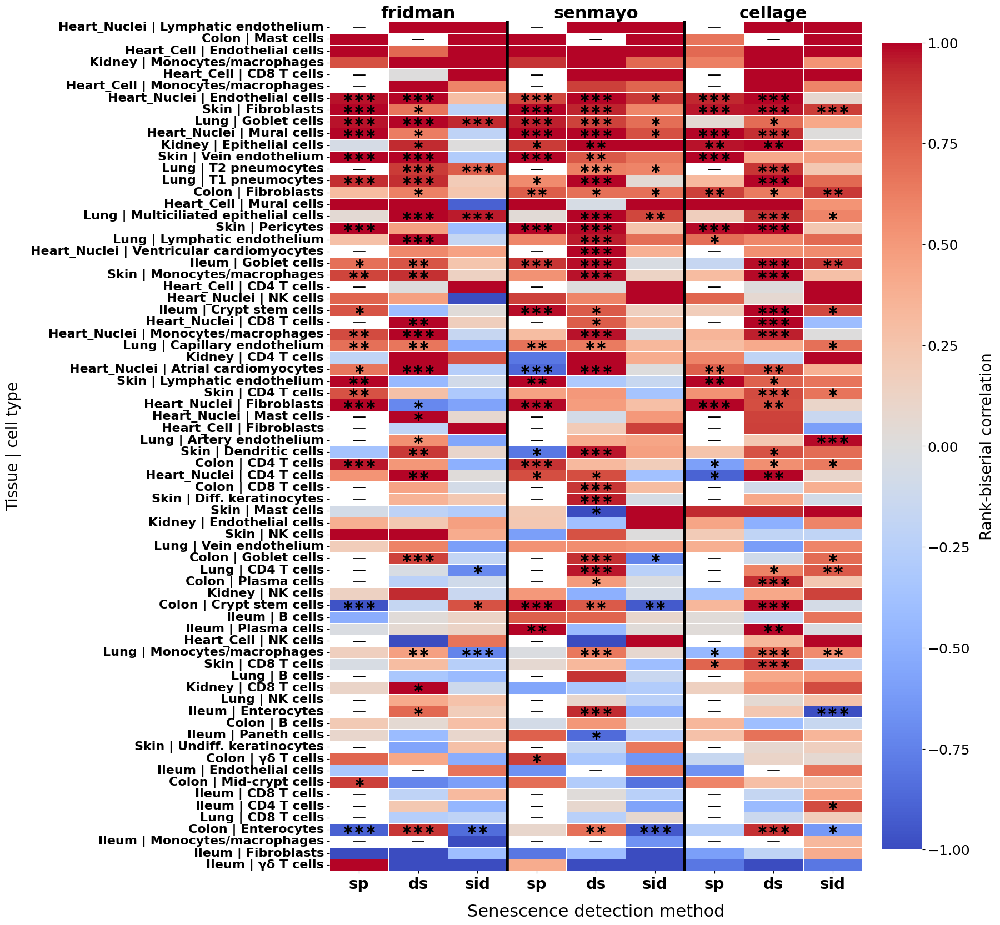

In [ ]:
"""Основная визуализация — единый heatmap RBC
все signatures × methods на одной фигуре"""

# ============================================================
# ROW ORDER
# Sort tissue × cell type by mean RBC
# across all methods and signatures
# ============================================================
row_order = (
    results_df.groupby(["Tissue_global", "cell_type"], observed=True)["rank_biserial_r"]
    .mean()
    .sort_values(ascending=False)
    .index
)
row_order = [f"{tissue} | {cell_type}" for tissue, cell_type in row_order]


# PREPARE DATA
# columns = signature × method
heatmap_list = []

for sig in sen_sigs:
    df = results_df[results_df["signature"] == sig].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # rows = tissue × cell type
    # columns = methods
    heatmap_data = df.pivot(index="group", columns="method", values="rank_biserial_r")
    heatmap_data = heatmap_data.reindex(columns=methods)

    # Add signature to column names
    heatmap_data.columns = [f"{sig} | {method}" for method in heatmap_data.columns]
    heatmap_list.append(heatmap_data)


# Combine all signatures horizontally
heatmap_data = pd.concat(heatmap_list, axis=1)

# Apply common row order
available_rows = [group for group in row_order if group in heatmap_data.index]
heatmap_data = heatmap_data.reindex(available_rows)


# FIGURE
fig, ax = plt.subplots(figsize=(18, 18))

sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot=False,
    cbar=True,
    cbar_kws={
        "label": "Rank-biserial correlation",
        "pad": 0.03,
        "shrink": 0.95,
    },
    yticklabels=True,
)

# Y AXIS
ax.set_yticks(np.arange(len(heatmap_data.index)) + 0.5)
ax.set_yticklabels(heatmap_data.index, rotation=0, fontsize=16, fontweight="semibold")
ax.set_ylabel("Tissue | cell type", fontsize=20, labelpad=12)

# X AXIS — METHODS
ax.set_xticks(np.arange(len(heatmap_data.columns)) + 0.5)
ax.set_xticklabels(
    methods * len(sen_sigs), rotation=0, fontsize=20, fontweight="semibold"
)
ax.set_xlabel("Senescence detection method", fontsize=22, labelpad=15)

# MISSING VALUES
for row_idx in range(len(heatmap_data.index)):
    for col_idx in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[row_idx, col_idx]):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=18,
                # fontweight="bold",
            )

# SIGNIFICANCE ANNOTATIONS
for col_idx, column in enumerate(heatmap_data.columns):
    # Parse signature and method
    sig, method = column.split(" | ", 1)
    df = results_df[results_df["signature"] == sig].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    for row_idx, group_name in enumerate(heatmap_data.index):
        row = df[(df["group"] == group_name) & (df["method"] == method)]

        if row.empty:
            continue

        label = row["significance"].iloc[0]

        if pd.notna(label) and label != "":
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=18,
                fontweight="bold",
            )

# SIGNATURE LABELS
n_methods = len(methods)

for i, sig in enumerate(sen_sigs):
    start = i * n_methods
    end = (i + 1) * n_methods
    center = (start + end) / 2

    ax.text(
        center,
        1,
        sig,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold",
    )


# SEPARATORS BETWEEN SIGNATURES
# Make these even more prominent
for i in range(1, len(sen_sigs)):
    x = i * n_methods
    ax.axvline(x, color="black", linewidth=4, zorder=11)

# COLORBAR
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
cbar.set_label("Rank-biserial correlation", fontsize=20, labelpad=12)

# FINAL LAYOUT
fig.subplots_adjust(top=0.93, bottom=0.08, left=0.27, right=0.92)
plt.show()

☝☝☝

Цвет показывает силу эффекта

Звёздочка показывает FDR.

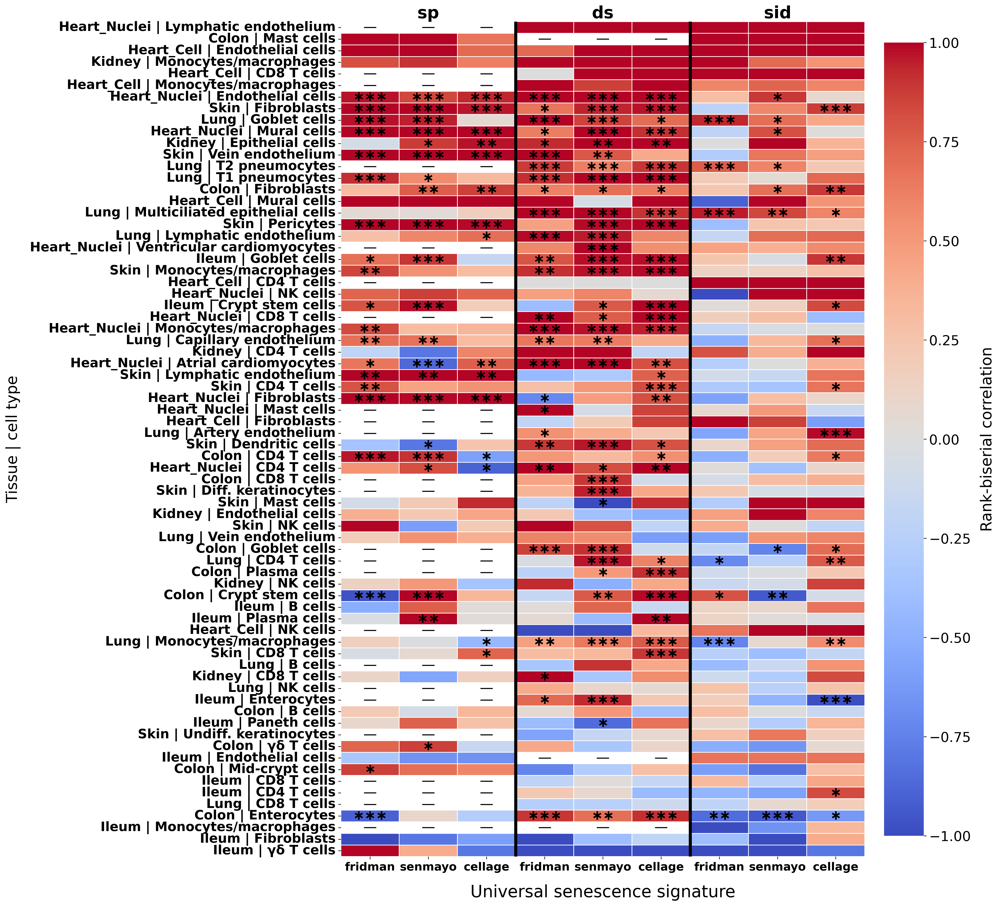

In [ ]:
"""Основная визуализация — единый heatmap RBC
все methods × signatures на одной фигуре"""

# ROW ORDER
# Sort tissue × cell type by mean RBC
# across all methods and signatures
# ============================================================
row_order = (
    results_df.groupby(["Tissue_global", "cell_type"], observed=True)["rank_biserial_r"]
    .mean()
    .sort_values(ascending=False)
    .index
)
row_order = [f"{tissue} | {cell_type}" for tissue, cell_type in row_order]

# PREPARE DATA
# columns = method × signature
heatmap_list = []

for method in methods:
    df = results_df[results_df["method"] == method].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # rows = tissue × cell type
    # columns = signatures

    heatmap_data = df.pivot(
        index="group", columns="signature", values="rank_biserial_r"
    )

    heatmap_data = heatmap_data.reindex(columns=sen_sigs)

    # Add method to column names
    heatmap_data.columns = [
        f"{method} | {signature}" for signature in heatmap_data.columns
    ]

    heatmap_list.append(heatmap_data)

# Combine all methods horizontally
heatmap_data = pd.concat(heatmap_list, axis=1)

# Apply common row order
available_rows = [group for group in row_order if group in heatmap_data.index]

heatmap_data = heatmap_data.reindex(available_rows)

# FIGURE
fig, ax = plt.subplots(figsize=(18, 18), dpi=300)

sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap="coolwarm",
    center=0,
    vmin=-1,
    vmax=1,
    linewidths=0.5,
    linecolor="white",
    annot=False,
    cbar=True,
    cbar_kws={
        "label": "Rank-biserial correlation",
        "pad": 0.03,
        "shrink": 0.95,
    },
    yticklabels=True,
)

# Y AXIS
ax.set_yticks(np.arange(len(heatmap_data.index)) + 0.5)
ax.set_yticklabels(heatmap_data.index, rotation=0, fontsize=17, fontweight="semibold")
ax.set_ylabel("Tissue | cell type", fontsize=20, labelpad=12)

# X AXIS — SIGNATURES
ax.set_xticks(np.arange(len(heatmap_data.columns)) + 0.5)
ax.set_xticklabels(
    sen_sigs * len(methods), rotation=0, fontsize=15, fontweight="semibold"
)
ax.set_xlabel("Universal senescence signature", fontsize=22, labelpad=15)

# MISSING VALUES
for row_idx in range(len(heatmap_data.index)):
    for col_idx in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[row_idx, col_idx]):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=18,
                # fontweight="bold",
            )

# SIGNIFICANCE ANNOTATIONS
for col_idx, column in enumerate(heatmap_data.columns):
    # Parse method and signature
    method, signature = column.split(" | ", 1)

    df = results_df[results_df["method"] == method].copy()

    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    for row_idx, group_name in enumerate(heatmap_data.index):
        row = df[(df["group"] == group_name) & (df["signature"] == signature)]

        if row.empty:
            continue

        label = row["significance"].iloc[0]

        if pd.notna(label) and label != "":
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                label,
                ha="center",
                va="center",
                fontsize=18,
                fontweight="bold",
            )

# METHOD LABELS
n_signatures = len(sen_sigs)

for i, method in enumerate(methods):
    start = i * n_signatures
    end = (i + 1) * n_signatures
    center = (start + end) / 2

    ax.text(
        center,
        1,
        method,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold",
    )

# SEPARATORS BETWEEN METHODS
for i in range(1, len(methods)):
    x = i * n_signatures
    ax.axvline(x, color="black", linewidth=4, zorder=11)

# COLORBAR
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
cbar.set_label("Rank-biserial correlation", fontsize=20, labelpad=12)

# FINAL LAYOUT
fig.subplots_adjust(top=0.93, bottom=0.08, left=0.27, right=0.92)
plt.show()

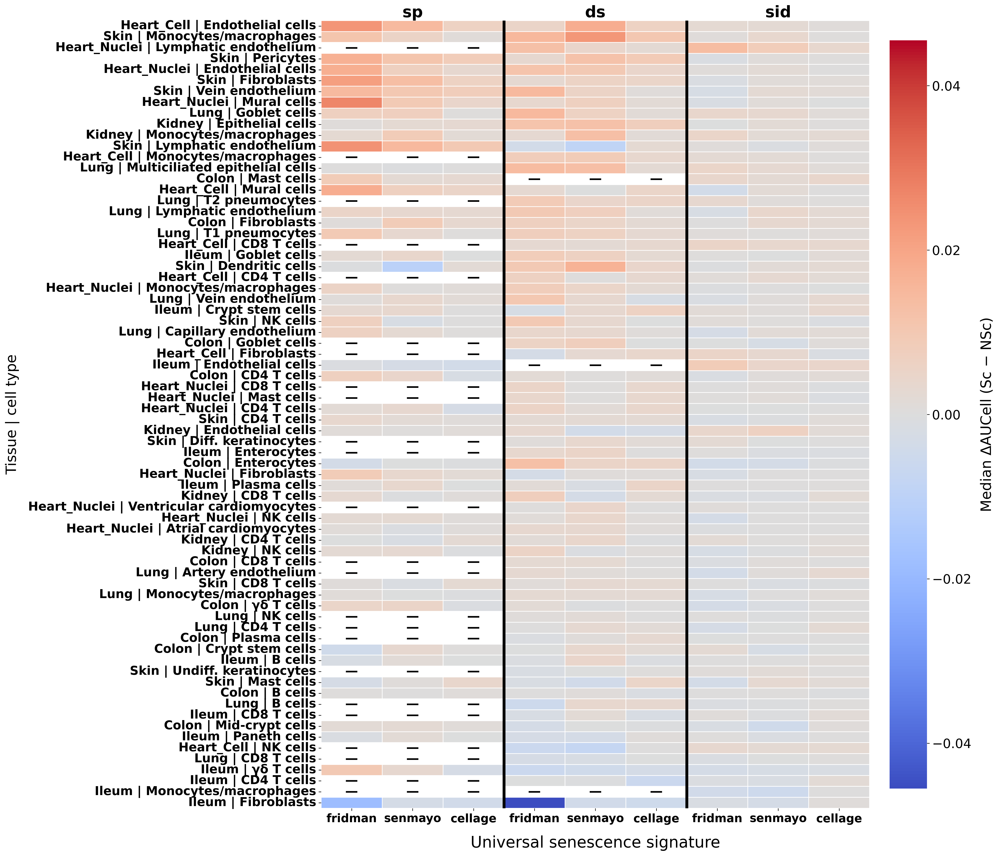

In [ ]:
"""Heatmap of median ΔAUCell for all methods × signatures"""

# ============================================================
# ROW ORDER
# Sort tissue × cell type by mean ΔAUCell
# across all methods and signatures
row_order = (
    results_df.groupby(["Tissue_global", "cell_type"], observed=True)[
        "median_AUCell_delta"
    ]
    .mean()
    .sort_values(ascending=False)
    .index
)

row_order = [f"{tissue} | {cell_type}" for tissue, cell_type in row_order]

# PREPARE DATA
# columns = method × signature
heatmap_list = []

for method in methods:
    df = results_df[results_df["method"] == method].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)
    # rows = tissue × cell type
    # columns = signatures
    heatmap_data = df.pivot(
        index="group", columns="signature", values="median_AUCell_delta"
    )
    heatmap_data = heatmap_data.reindex(columns=sen_sigs)
    # Add method to column names
    heatmap_data.columns = [
        f"{method} | {signature}" for signature in heatmap_data.columns
    ]
    heatmap_list.append(heatmap_data)

# Combine all methods horizontally
heatmap_data = pd.concat(heatmap_list, axis=1)
# Apply common row order
available_rows = [group for group in row_order if group in heatmap_data.index]
heatmap_data = heatmap_data.reindex(available_rows)

# COLOR SCALE
# One symmetric scale for the entire heatmap
max_abs = np.nanmax(np.abs(heatmap_data.values))

# FIGURE
fig, ax = plt.subplots(figsize=(20, 18), dpi=300)

sns.heatmap(
    heatmap_data,
    ax=ax,
    cmap="coolwarm",
    center=0,
    vmin=-max_abs,
    vmax=max_abs,
    linewidths=0.5,
    linecolor="white",
    annot=False,
    cbar=True,
    cbar_kws={
        "label": "Median ΔAUCell (Sc − NSc)",
        "pad": 0.03,
        "shrink": 0.95,
    },
    yticklabels=True,
)

# MISSING VALUES
for row_idx in range(len(heatmap_data.index)):
    for col_idx in range(len(heatmap_data.columns)):
        if pd.isna(heatmap_data.iloc[row_idx, col_idx]):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=18,
                fontweight="bold",
            )

# Y AXIS
ax.set_yticks(np.arange(len(heatmap_data.index)) + 0.5)
ax.set_yticklabels(heatmap_data.index, rotation=0, fontsize=17, fontweight="semibold")
ax.set_ylabel("Tissue | cell type", fontsize=20, labelpad=12)

# X AXIS — SIGNATURES
ax.set_xticks(np.arange(len(heatmap_data.columns)) + 0.5)
ax.set_xticklabels(
    sen_sigs * len(methods), rotation=0, fontsize=16, fontweight="semibold"
)
ax.set_xlabel("Universal senescence signature", fontsize=22, labelpad=15)

# METHOD LABELS
n_signatures = len(sen_sigs)
for i, method in enumerate(methods):
    start = i * n_signatures
    end = (i + 1) * n_signatures
    center = (start + end) / 2
    ax.text(
        center,
        1,
        method,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=22,
        fontweight="bold",
    )

# SEPARATORS BETWEEN METHODS
for i in range(1, len(methods)):
    x = i * n_signatures
    ax.axvline(x, color="black", linewidth=4, zorder=11)

# COLORBAR
cbar = ax.collections[0].colorbar
cbar.ax.tick_params(labelsize=18)
cbar.set_label("Median ΔAUCell (Sc − NSc)", fontsize=20, labelpad=12)

# FINAL LAYOUT
fig.subplots_adjust(top=0.93, bottom=0.08, left=0.27, right=0.92)

plt.show()

NB: здесь не следует визуально сравнивать абсолютную интенсивность между тремя хитмапами как будто шкалы идентичны. Они нужны прежде всего для понимания направления и величины эффекта внутри конкретной signature

In [23]:
"""Paired method comparison using RBC — paired dot/line plot
Cоединяем результаты трёх методов
Каждая точка = один tissue × cell_type
"""


def plot_paired_rbc(results_df, signature, figsize=(8, 7), alpha_lines=0.25):

    df = results_df[results_df["signature"] == signature].copy()

    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # Keep only groups where at least two methods are available
    counts = df.groupby("group")["method"].nunique()
    valid_groups = counts[counts >= 2].index
    df = df[df["group"].isin(valid_groups)].copy()
    group_order = sorted(df["group"].unique())
    method_x = {method: i for i, method in enumerate(methods)}

    fig, ax = plt.subplots(figsize=figsize)

    for group in group_order:
        group_df = df[df["group"] == group]
        available = set(group_df["method"])

        # Connect methods for the same tissue × cell type
        if len(available) >= 2:
            ordered = group_df.set_index("method").reindex(methods)

            ax.plot(
                [method_x[m] for m in methods if m in available],
                [ordered.loc[m, "rank_biserial_r"] for m in methods if m in available],
                linewidth=1,
                alpha=alpha_lines,
            )

        # Plot individual method points
        for method in methods:
            row = group_df[group_df["method"] == method]

            if len(row) == 0:
                continue

            value = row["rank_biserial_r"].iloc[0]

            ax.scatter(method_x[method], value, s=35, zorder=3)

    ax.axhline(0, linestyle="--", linewidth=1)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods)
    ax.set_ylabel("Rank-biserial correlation")
    ax.set_xlabel("Senescence detection method")
    ax.set_title(f"{signature}: method comparison")
    ax.set_ylim(-1.05, 1.05)

    plt.tight_layout()

    return fig, ax

In [24]:
len(obs.cell_type.unique())

30

In [26]:
def plot_paired_rbc(
    results_df, signature, methods, color_dict, figsize=(8, 7), alpha_lines=0.4
):

    df = results_df[results_df["signature"] == signature].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # Оставляем только группы, где есть хотя бы два метода
    counts = df.groupby("group")["method"].nunique()
    valid_groups = counts[counts >= 2].index
    df = df[df["group"].isin(valid_groups)].copy()
    group_order = sorted(df["group"].unique())

    method_x = {method: i for i, method in enumerate(methods)}

    fig, ax = plt.subplots(figsize=figsize)

    # Сид для воспроизводимости разнесения точек (jitter)
    rng = np.random.default_rng(seed=42)

    for group in group_order:
        group_df = df[df["group"] == group]
        available = set(group_df["method"])

        # Определяем цвет для текущей группы по её cell_type
        cell_type = group_df["cell_type"].iloc[0]
        current_color = color_dict.get(cell_type, "gray")

        # Генерируем индивидуальное случайное смещение по X для этой группы (-0.08 до 0.08)
        # Это разнесет линии и точки одного cell_type x tissue, чтобы они не накладывались
        jitter = rng.uniform(-0.08, 0.08)

        # Соединяем методы линией
        if len(available) >= 2:
            ordered = group_df.set_index("method").reindex(methods)

            x_values = [method_x[m] + jitter for m in methods if m in available]
            y_values = [
                ordered.loc[m, "rank_biserial_r"] for m in methods if m in available
            ]

            ax.plot(
                x_values,
                y_values,
                linewidth=1.8,  # Линии стали толще
                alpha=alpha_lines,  # Прозрачность линий
                color=current_color,  # Цвет линии совпадает с точкой
                zorder=2,
            )

        # Отрисовка индивидуальных точек
        for method in methods:
            row = group_df[group_df["method"] == method]
            if len(row) == 0:
                continue

            value = row["rank_biserial_r"].iloc[0]

            ax.scatter(
                method_x[method] + jitter,  # Применяем тот же jitter, что и для линии
                value,
                s=30,  # Размер точек чуть уменьшен (был 35)
                color=current_color,  # Явный цвет из словаря
                alpha=0.4,  # Прозрачность на 0.7
                zorder=3,
            )

    ax.axhline(0, linestyle="--", linewidth=1, color="black", alpha=0.5)
    ax.set_xticks(range(len(methods)))
    ax.set_xticklabels(methods)
    ax.set_ylabel("Rank-biserial correlation")
    ax.set_xlabel("Senescence detection method")
    ax.set_title(f"{signature}: method comparison")
    ax.set_ylim(-1.05, 1.05)

    plt.tight_layout()
    return fig, ax


def plot_separate_legend(color_dict):
    # Создаем фигуру под размер легенды
    fig, ax = plt.subplots(figsize=(10, 6))
    ax.axis("off")  # Прячем оси самого графика

    # Создаем "фиктивные" элементы для легенды
    legend_elements = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=color,
            markersize=8,
            label=cell_type,
        )
        for cell_type, color in color_dict.items()
    ]

    # Отрисовываем легенду по центру в 3 столбца (по 10 элементов в каждом)
    ax.legend(
        handles=legend_elements,
        loc="center",
        ncol=3,
        frameon=True,
        fontsize=10,
        title="Cell Types",
    )

    plt.tight_layout()
    plt.show()


In [ ]:
import matplotlib.cm as cm


def plot_paired_rbc_all_signatures(
    results_df,
    signatures,
    methods,
    color_dict,
    figsize=(16, 9),
    alpha_lines=0.4,
    jitter_width=0.1,
):
    """
    Одна общая фигура для нескольких сигнатур.

    Для каждой комбинации Tissue_global × cell_type
    точки разных методов соединяются одной линией.

    Цвет определяется только cell_type.
    """

    # Подготовка данных
    df = results_df[results_df["signature"].isin(signatures)].copy()
    df["group"] = df["Tissue_global"].astype(str) + " | " + df["cell_type"].astype(str)

    # Оставляем только Tissue × cell_type,
    # где присутствуют минимум 2 метода
    counts = df.groupby(["signature", "group"])["method"].nunique()
    valid_groups = counts[counts >= 2].index
    df = df.set_index(["signature", "group"])
    df = df.loc[df.index.isin(valid_groups)].reset_index()

    # Параметры расположения блоков
    n_methods = len(methods)
    # Расстояние между соседними методами
    method_spacing = 0.8
    # Дополнительное расстояние между сигнатурами
    signature_gap = 0.5
    # Позиции методов внутри одного блока
    method_positions = np.arange(n_methods) * method_spacing
    # Начальные позиции блоков сигнатур
    block_width = (n_methods - 1) * method_spacing

    signature_starts = [
        i * (block_width + signature_gap) for i in range(len(signatures))
    ]

    # Полные X-позиции методов
    x_positions = {}

    for sig, start in zip(signatures, signature_starts):
        x_positions[sig] = {
            method: start + method_positions[i] for i, method in enumerate(methods)
        }

    # Figure
    fig, ax = plt.subplots(figsize=figsize, dpi=300)
    rng = np.random.default_rng(seed=42)

    # Отрисовка линий и точек
    for sig in signatures:
        sig_df = df[df["signature"] == sig]
        group_order = sorted(sig_df["group"].unique())

        for group in group_order:
            group_df = sig_df[sig_df["group"] == group]
            available = set(group_df["method"])

            # Цвет определяется только cell_type
            cell_type = group_df["cell_type"].iloc[0]
            current_color = color_dict.get(cell_type, "gray")

            # Один jitter для всей линии,
            # поэтому точки одной Tissue × cell_type остаются
            # точно над своей линией
            jitter = rng.uniform(-jitter_width, jitter_width)

            # Линия между методами
            if len(available) >= 2:
                ordered = group_df.set_index("method").reindex(methods)

                x_values = [
                    x_positions[sig][m] + jitter for m in methods if m in available
                ]

                y_values = [
                    ordered.loc[m, "rank_biserial_r"] for m in methods if m in available
                ]

                ax.plot(
                    x_values,
                    y_values,
                    linewidth=1.8,
                    alpha=alpha_lines,
                    color=current_color,
                    zorder=2,
                )

            # Точки
            for method in methods:
                row = group_df[group_df["method"] == method]

                if len(row) == 0:
                    continue

                value = row["rank_biserial_r"].iloc[0]

                ax.scatter(
                    x_positions[sig][method] + jitter,
                    value,
                    s=80,
                    color=current_color,
                    alpha=0.65,
                    zorder=3,
                )

    # Нулевая линия
    ax.axhline(
        0,
        linestyle="--",
        linewidth=1.2,
        color="black",
        alpha=0.5,
        zorder=1,
    )

    # X-axis
    all_x = []
    for sig in signatures:
        for method in methods:
            all_x.append(x_positions[sig][method])

    ax.set_xticks(all_x)
    ax.set_xticklabels(
        methods * len(signatures),
        fontsize=16,
        fontweight="semibold",
    )

    ax.set_xlabel(
        "Senescence detection method\n",
        fontsize=18,
        # fontweight="semibold",
        labelpad=12,
    )

    # Подписи сигнатур над каждым блоком
    for sig, start in zip(signatures, signature_starts):
        center = start + block_width / 2

        ax.text(
            center,
            1.0,
            sig,
            transform=ax.get_xaxis_transform(),
            ha="center",
            va="bottom",
            fontsize=18,
            fontweight="semibold",
        )

    # ============================================================
    # Y-axis
    # ============================================================

    ax.set_ylabel(
        "Rank-biserial correlation",
        fontsize=18,
        # fontweight="semibold",
    )

    ax.set_ylim(-1.05, 1.05)
    ax.tick_params(
        axis="y",
        labelsize=13,
    )
    ax.tick_params(
        axis="x",
        length=0,
        pad=8,
    )

    # Немного воздуха между блоками
    ax.set_xlim(
        min(all_x) - 0.2,
        max(all_x) + 0.2,
    )

    # Убираем верхнюю и правую рамки
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.grid(
        axis="y",
        alpha=0.2,
        linewidth=0.8,
    )

    plt.tight_layout()

    return fig, ax


def add_cell_type_legend(fig, color_dict, ncol=5):
    """помещает легенду под основным графиком"""
    legend_elements = [
        plt.Line2D(
            [0],
            [0],
            marker="o",
            color="w",
            markerfacecolor=color,
            markersize=9,
            label=cell_type,
        )
        for cell_type, color in color_dict.items()
    ]

    fig.legend(
        handles=legend_elements,
        loc="lower center",
        bbox_to_anchor=(0.55, -0.12),
        ncol=ncol,
        frameon=False,
        fontsize=12,
        title="\nCell Types",
        title_fontsize=15,
    )

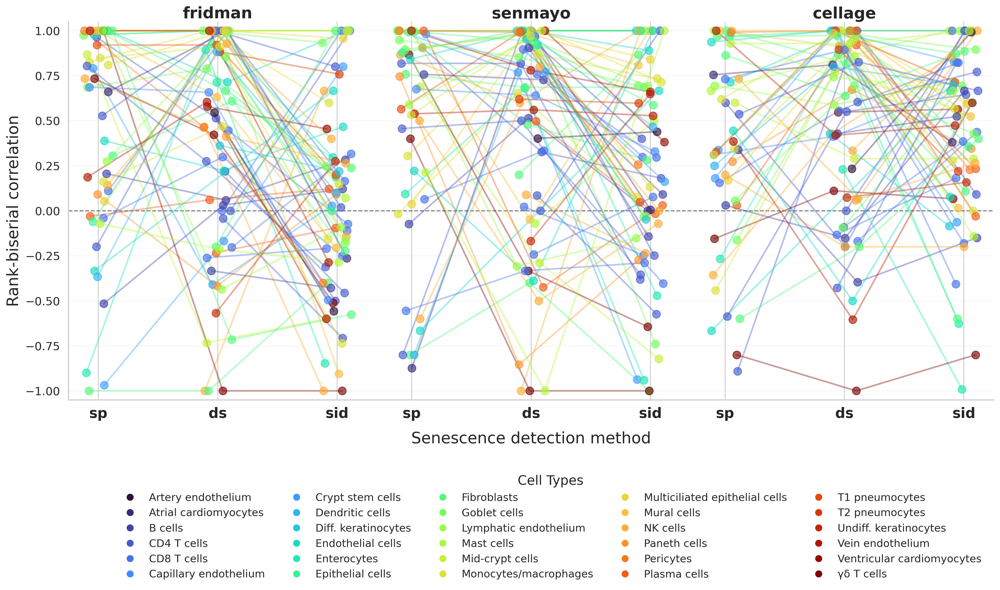

In [ ]:
# Все cell types
all_cell_types = sorted(results_df["cell_type"].dropna().unique())

# Цвета cell types
colors = cm.turbo(np.linspace(0, 1, len(all_cell_types)))

color_dict = dict(zip(all_cell_types, colors))

# ============================================================
# Одна общая фигура
# ============================================================

fig, ax = plot_paired_rbc_all_signatures(
    results_df=results_df,
    signatures=sen_sigs,
    methods=methods,
    color_dict=color_dict,
    figsize=(16, 10),
)

# Легенда снизу
add_cell_type_legend(
    fig,
    color_dict,
    ncol=5,
)

# Оставляем место под легенду
plt.subplots_adjust(
    bottom=0.18,
    top=0.78,
)

plt.show()

In [82]:
results_df.head()

,method,signature,Tissue_global,cell_type,n_donors,median_AUCell_delta,fraction_positive,wilcoxon_statistic,p_value,FDR,rank_biserial_r,rbc_ci_low,rbc_ci_high,significance
0,ds,cellage,Colon,B cells,16,-0.001133,0.250000,41.0,0.175354,0.257435,-0.397059,-0.955882,0.147059,
1,ds,cellage,Colon,CD4 T cells,23,0.001100,0.739130,62.0,0.019557,0.048195,0.550725,0.144746,0.884058,∗
2,ds,cellage,Colon,CD8 T cells,21,0.000279,0.571429,105.0,0.733470,0.843490,-0.090909,-0.558442,0.480952,
3,ds,cellage,Colon,Crypt stem cells,19,0.002084,0.947368,1.0,0.000008,0.000053,0.989474,0.936842,1.000000,∗∗∗
4,ds,cellage,Colon,Enterocytes,24,0.004994,0.958333,13.0,0.000010,0.000066,0.913333,0.700000,1.000000,∗∗∗


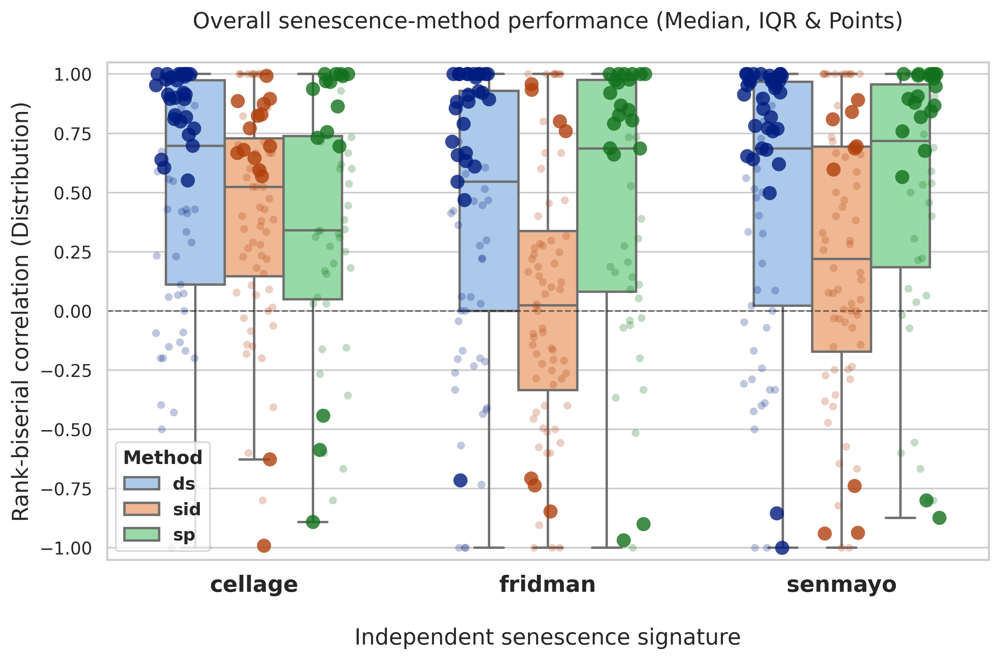

In [ ]:
"""Method ranking across signatures
(median, IQR, 1.5xIQR, values)"""

# Настраиваем стиль, чтобы графики выглядели аккуратно
sns.set_theme(style="whitegrid")

fig, ax = plt.subplots(figsize=(9, 6), dpi=300)

# 1. Строим "коробочки" (медиана, IQR, усы), имитирующие барплоты
# Передаем исходный results_df, чтобы seaborn сам посчитал квартили
sns.boxplot(
    data=results_df,
    x="signature",
    y="rank_biserial_r",
    hue="method",
    palette="pastel",  # Мягкие цвета для подложки-коробок
    width=0.6,  # Ширина столбцов-коробок
    fliersize=0,  # Прячем стандартные точки-выбросы (их нарисует stripplot ниже)
    linewidth=1.5,  # Толщина границ
    ax=ax,
)

significant = results_df["significance"] != ""

sns.stripplot(
    data=results_df[~significant],
    x="signature",
    y="rank_biserial_r",
    hue="method",
    palette="dark",
    size=5,
    alpha=0.25,
    dodge=True,
    jitter=0.2,
    legend=False,
    ax=ax,
)

sns.stripplot(
    data=results_df[significant],
    x="signature",
    y="rank_biserial_r",
    hue="method",
    palette="dark",
    size=9,
    alpha=0.8,
    dodge=True,
    jitter=0.2,
    legend=False,
    ax=ax,
)

# Нулевая линия
ax.axhline(0, linestyle="--", linewidth=1, color="black", alpha=0.5)

# Оформление осей и заголовков
ax.set_ylabel("Rank-biserial correlation (Distribution)", fontsize=14)
ax.set_xlabel(f"\nIndependent senescence signature", fontsize=14)
ax.set_title(
    "Overall senescence-method performance (Median, IQR & Points)\n", fontsize=14
)
# ax.tick_params(axis='x', labelfont={'weight': 'semibold', 'size': 14})
for label in ax.get_xticklabels():
    label.set_fontweight("semibold")
    label.set_fontsize(14)

# Ограничиваем ось Y под масштаб корреляции
ax.set_ylim(-1.05, 1.05)

# Настройка легенды (чтобы не было дублирования из-за hue)
handles, labels = ax.get_legend_handles_labels()
# Берем только первую половину хэндлов (они относятся к boxplot)
ax.legend(
    handles[: len(results_df["method"].unique())],
    labels[: len(results_df["method"].unique())],
    title="Method",
    loc="lower left",
    prop={"weight": "semibold"},  # Делает полужирным текст элементов
    title_fontproperties={"weight": "semibold"},  # Делает полужирным заголовок "Method"
)

plt.tight_layout()
plt.show()


### Анализ RBC метриками конкордантности

In [86]:
from sklearn.metrics import cohen_kappa_score, matthews_corrcoef
from statsmodels.stats.inter_rater import fleiss_kappa

In [87]:
"""RBC values for the same `tissue × cell type × signature` across methods"""

rbc_wide = results_df.pivot_table(
    index=["signature", "Tissue_global", "cell_type"],
    columns="method",
    values=["rank_biserial_r", "p_value", "FDR"],
    aggfunc="first",
)

# Flatten MultiIndex columns
rbc_wide.columns = [f"{value}_{method}" for value, method in rbc_wide.columns]

rbc_wide = rbc_wide.reset_index()

display(rbc_wide.shape)
rbc_wide.head()

(216, 12)

,signature,Tissue_global,cell_type,FDR_ds,FDR_sid,FDR_sp,p_value_ds,p_value_sid,p_value_sp,rank_biserial_r_ds,rank_biserial_r_sid,rank_biserial_r_sp
0,cellage,Colon,B cells,0.257435,0.792834,0.409589,0.175354,0.638672,0.252228,-0.397059,-0.150000,0.338235
1,cellage,Colon,CD4 T cells,0.048195,0.029988,0.039342,0.019557,0.005414,0.012295,0.550725,0.644928,-0.586957
2,cellage,Colon,CD8 T cells,0.843490,0.303931,NaN,0.733470,0.128078,NaN,-0.090909,0.385281,NaN
3,cellage,Colon,Crypt stem cells,0.000053,0.928571,0.403425,0.000008,0.809185,0.210117,0.989474,-0.063158,0.336842
4,cellage,Colon,Enterocytes,0.000066,0.030331,0.409589,0.000010,0.005898,0.264343,0.913333,-0.626667,-0.266667


In [88]:
"""RBC direction"""

for method in methods:
    rbc_wide[f"direction_{method}"] = np.sign(rbc_wide[f"rank_biserial_r_{method}"])

    # RBC = 0 → направление не определено
    rbc_wide.loc[rbc_wide[f"rank_biserial_r_{method}"] == 0, f"direction_{method}"] = (
        np.nan
    )


"""Significance"""

for method in methods:
    rbc_wide[f"significant_{method}"] = rbc_wide[f"FDR_{method}"] < 0.05

In [89]:
"""Group-level (signature × Tissue × cell_type) agreement"""

agreement_df = rbc_wide[
    [
        "signature",
        "Tissue_global",
        "cell_type",
        "direction_sp",
        "direction_sid",
        "direction_ds",
        "significant_sp",
        "significant_sid",
        "significant_ds",
    ]
].copy()

In [90]:
"""Pairwise agreement"""

agreement_df["agreement_sp_sid"] = np.where(
    agreement_df["direction_sp"].notna() & agreement_df["direction_sid"].notna(),
    (agreement_df["direction_sp"] == agreement_df["direction_sid"]).astype(int),
    np.nan,
)

agreement_df["agreement_sp_ds"] = np.where(
    agreement_df["direction_sp"].notna() & agreement_df["direction_ds"].notna(),
    (agreement_df["direction_sp"] == agreement_df["direction_ds"]).astype(int),
    np.nan,
)

agreement_df["agreement_sid_ds"] = np.where(
    agreement_df["direction_sid"].notna() & agreement_df["direction_ds"].notna(),
    (agreement_df["direction_sid"] == agreement_df["direction_ds"]).astype(int),
    np.nan,
)


"""Agreement for all 3"""

agreement_df["agreement_all3"] = np.where(
    agreement_df[["direction_sp", "direction_sid", "direction_ds"]].notna().all(axis=1),
    (
        (agreement_df["direction_sp"] == agreement_df["direction_sid"])
        & (agreement_df["direction_sp"] == agreement_df["direction_ds"])
    ).astype(int),
    np.nan,
)

# agreement_df — основной group-level датафрейм

In [91]:
"""Significant group-level agreement"""

agreement_sig_df = agreement_df.copy()

agreement_sig_df["agreement_sp_sid"] = np.where(
    agreement_sig_df["significant_sp"]
    & agreement_sig_df["significant_sid"]
    & agreement_sig_df["direction_sp"].notna()
    & agreement_sig_df["direction_sid"].notna(),
    (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_sid"]).astype(int),
    np.nan,
)

agreement_sig_df["agreement_sp_ds"] = np.where(
    agreement_sig_df["significant_sp"]
    & agreement_sig_df["significant_ds"]
    & agreement_sig_df["direction_sp"].notna()
    & agreement_sig_df["direction_ds"].notna(),
    (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_ds"]).astype(int),
    np.nan,
)

agreement_sig_df["agreement_sid_ds"] = np.where(
    agreement_sig_df["significant_sid"]
    & agreement_sig_df["significant_ds"]
    & agreement_sig_df["direction_sid"].notna()
    & agreement_sig_df["direction_ds"].notna(),
    (agreement_sig_df["direction_sid"] == agreement_sig_df["direction_ds"]).astype(int),
    np.nan,
)

agreement_sig_df["agreement_all3"] = np.where(
    agreement_sig_df["significant_sp"]
    & agreement_sig_df["significant_sid"]
    & agreement_sig_df["significant_ds"]
    & agreement_sig_df[["direction_sp", "direction_sid", "direction_ds"]]
    .notna()
    .all(axis=1),
    (
        (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_sid"])
        & (agreement_sig_df["direction_sp"] == agreement_sig_df["direction_ds"])
    ).astype(int),
    np.nan,
)


# agreement_sig_df - такой же group-lvl датафрейм согласованностей, но с фильтром по FDR

**Summary metrics для пар методов**

Для каждой пары (`signature × method`) считаем следующие метрики:

- n_groups
- n_concordant
- percent_agreement
- cohen_kappa
- jaccard_positive
- MCC (как доп. метрика - см ниже)

> MCC (Matthews correlation coefficient) — коэффициент корреляции Мэтьюса. Это метрика согласованности двух бинарных классификаций, *включая способность различать оба класса* (т.е. в группе должны присутствовать оба класса, иначе критерий становится неинформативным)
> 
> (в данном случае две классификации — это направления RBC двух методов)
> 
> Напр.
> ```
> SP  = [1, 1, 0, 0]
> SID = [1, 0, 0, 1]
> ```
> 
> В терминах классификации:
> 
> - TP — оба положительные;
> - TN — оба отрицательные;
> - FP — первый положительный, второй отрицательный;
> - FN — первый отрицательный, второй положительный.
> 
> $$MCC = \frac{TP \times TN - FP \times FN}{\sqrt{(TP + FP)(TP + FN)(TN + FP)(TN + FN)}}$$
> 
> | MCC | Интерпретация                      |
> | --- | ---------------------------------- |
> | +1  | полное совпадение направлений      |
> | 0   | согласие не лучше случайного       |
> | −1  | полное противоположное направление |
> 


In [92]:
def calculate_pairwise_metrics(df, method1, method2, agreement_col):
    """Calculate aggregate agreement metrics for one method pair."""

    mask = df[f"direction_{method1}"].notna() & df[f"direction_{method2}"].notna()

    sub = df.loc[
        mask,
        [
            "signature",
            f"direction_{method1}",
            f"direction_{method2}",
        ],
    ].copy()

    if len(sub) == 0:
        return None

    y1 = sub[f"direction_{method1}"].astype(int)
    y2 = sub[f"direction_{method2}"].astype(int)

    # Percent agreement
    percent_agreement = np.mean(y1 == y2) * 100

    # Cohen's kappa
    kappa = cohen_kappa_score(y1, y2)

    # Jaccard для положительного направления
    positive_1 = y1 == 1
    positive_2 = y2 == 1

    intersection = (positive_1 & positive_2).sum()
    union = (positive_1 | positive_2).sum()

    jaccard = intersection / union if union > 0 else np.nan

    # MCC
    if y1.nunique() > 1 and y2.nunique() > 1:
        mcc = matthews_corrcoef(y1, y2)
    else:
        mcc = np.nan

    return {
        "signature": sub["signature"].iloc[0],
        "method_pair": f"{method1}–{method2}",
        "n_groups": len(sub),
        "n_concordant": np.sum(y1 == y2),
        "percent_agreement": percent_agreement,
        "cohen_kappa": kappa,
        "jaccard_positive": jaccard,
        "MCC": mcc,
    }

In [93]:
""" применение функции выше для каждой сен.сигнатуры"""

pair_results = []

for signature in agreement_df["signature"].dropna().unique():
    df_sig = agreement_df[agreement_df["signature"] == signature].copy()

    for method1, method2, agreement_col in [
        ("sp", "sid", "agreement_sp_sid"),
        ("sp", "ds", "agreement_sp_ds"),
        ("sid", "ds", "agreement_sid_ds"),
    ]:
        result = calculate_pairwise_metrics(df_sig, method1, method2, agreement_col)

        if result is not None:
            pair_results.append(result)

pair_metrics_df = pd.DataFrame(pair_results)

pair_metrics_df

,signature,method_pair,n_groups,n_concordant,percent_agreement,cohen_kappa,jaccard_positive,MCC
0,cellage,sp–sid,47,34,72.340426,0.072838,0.711111,0.074564
1,cellage,sp–ds,46,33,71.739130,0.062696,0.704545,0.062860
2,cellage,sid–ds,67,48,71.641791,0.066031,0.703125,0.066111
3,fridman,sp–sid,47,20,42.553191,-0.108297,0.372093,-0.137439
4,fridman,sp–ds,46,33,71.739130,0.138329,0.697674,0.138633
5,fridman,sid–ds,66,36,54.545455,0.090909,0.464286,0.103944
6,senmayo,sp–sid,46,28,60.869565,-0.032419,0.590909,-0.036487
7,senmayo,sp–ds,46,30,65.217391,-0.010989,0.636364,-0.011358
8,senmayo,sid–ds,66,42,63.636364,0.153846,0.586207,0.160357


In [94]:
""" применение функции выше для каждой сен.сигнатуры с учетом значимости по FDR"""

pair_sig_results = []

for signature in agreement_sig_df["signature"].dropna().unique():
    df_sig = agreement_sig_df[agreement_sig_df["signature"] == signature].copy()

    for method1, method2, agreement_col in [
        ("sp", "sid", "agreement_sp_sid"),
        ("sp", "ds", "agreement_sp_ds"),
        ("sid", "ds", "agreement_sid_ds"),
    ]:
        # Здесь agreement_col уже содержит NaN
        # для незначимых пар
        sub = df_sig[df_sig[agreement_col].notna()].copy()

        if len(sub) == 0:
            continue

        y1 = sub[f"direction_{method1}"].astype(int)
        y2 = sub[f"direction_{method2}"].astype(int)

        percent_agreement = np.mean(y1 == y2) * 100

        kappa = cohen_kappa_score(y1, y2)

        positive_1 = y1 == 1
        positive_2 = y2 == 1

        intersection = (positive_1 & positive_2).sum()
        union = (positive_1 | positive_2).sum()

        jaccard = intersection / union if union > 0 else np.nan

        if y1.nunique() > 1 and y2.nunique() > 1:
            mcc = matthews_corrcoef(y1, y2)
        else:
            mcc = np.nan

        pair_sig_results.append(
            {
                "signature": signature,
                "method_pair": f"{method1}–{method2}",
                "n_groups": len(sub),
                "n_concordant": np.sum(y1 == y2),
                "percent_agreement": percent_agreement,
                "cohen_kappa": kappa,
                "jaccard_positive": jaccard,
                "MCC": mcc,
            }
        )

pair_sig_metrics_df = pd.DataFrame(pair_sig_results)

pair_sig_metrics_df

,signature,method_pair,n_groups,n_concordant,percent_agreement,cohen_kappa,jaccard_positive,MCC
0,cellage,sp–sid,4,2,50.000000,0.000000,0.500000,NaN
1,cellage,sp–ds,13,10,76.923077,0.000000,0.769231,NaN
2,cellage,sid–ds,10,9,90.000000,0.000000,0.900000,NaN
3,fridman,sp–sid,3,2,66.666667,0.400000,0.500000,0.500000
4,fridman,sp–ds,13,11,84.615385,-0.083333,0.846154,-0.083333
5,fridman,sid–ds,5,3,60.000000,0.000000,0.600000,NaN
6,senmayo,sp–sid,5,4,80.000000,0.000000,0.800000,NaN
7,senmayo,sp–ds,16,14,87.500000,0.000000,0.875000,NaN
8,senmayo,sid–ds,9,6,66.666667,0.000000,0.666667,NaN


**Метрики для всех трёх методов**

для каждой сен.сигнатуры по методам считаем:

- percent agreement ( как доля групп, в которых *все три метода имеют одинаковое направление*)
- Fleiss' κ.

In [95]:
def calculate_all3_metrics(df):
    sub = df[
        df[["direction_sp", "direction_sid", "direction_ds"]].notna().all(axis=1)
    ].copy()

    if len(sub) == 0:
        return None

    directions = sub[["direction_sp", "direction_sid", "direction_ds"]].astype(int)

    # Все три одинаковы
    all3_agreement = (directions["direction_sp"] == directions["direction_sid"]) & (
        directions["direction_sp"] == directions["direction_ds"]
    )

    percent_agreement = all3_agreement.mean() * 100

    # Fleiss' kappa
    """!!! fleiss_kappa ожидает категории 0, 1, а у нас −1, +1 уже превратились в категории, поэтому выше мы считаем количества, а не передаём сами значения"""
    fleiss_data = []

    for _, row in directions.iterrows():
        n_positive = (row == 1).sum()
        n_negative = (row == -1).sum()

        fleiss_data.append([n_positive, n_negative])

    fleiss_data = np.asarray(fleiss_data)

    kappa = fleiss_kappa(fleiss_data, method="fleiss")

    return {
        "n_groups": len(sub),
        "n_concordant_all3": all3_agreement.sum(),
        "percent_agreement": percent_agreement,
        "fleiss_kappa": kappa,
    }

In [96]:
all3_results = []

for signature in agreement_df["signature"].dropna().unique():
    df_sig = agreement_df[agreement_df["signature"] == signature].copy()

    result = calculate_all3_metrics(df_sig)

    if result is not None:
        result["signature"] = signature
        all3_results.append(result)

all3_metrics_df = pd.DataFrame(all3_results)

all3_metrics_df

,n_groups,n_concordant_all3,percent_agreement,fleiss_kappa,signature
0,45,28,62.222222,0.138514,cellage
1,45,15,33.333333,-0.023761,fridman
2,44,23,52.272727,0.151515,senmayo


In [97]:
"""All 3 — только статистически значимые"""

all3_sig_results = []

for signature in agreement_sig_df["signature"].dropna().unique():
    df_sig = agreement_sig_df[agreement_sig_df["signature"] == signature].copy()

    sub = df_sig[df_sig["agreement_all3"].notna()].copy()

    if len(sub) == 0:
        continue

    directions = sub[["direction_sp", "direction_sid", "direction_ds"]].astype(int)

    all3_agreement = (directions["direction_sp"] == directions["direction_sid"]) & (
        directions["direction_sp"] == directions["direction_ds"]
    )

    percent_agreement = all3_agreement.mean()

    fleiss_data = []

    for _, row in directions.iterrows():
        n_positive = (row == 1).sum()
        n_negative = (row == -1).sum()

        fleiss_data.append([n_positive, n_negative])

    fleiss_data = np.asarray(fleiss_data)

    kappa = fleiss_kappa(fleiss_data, method="fleiss")

    all3_sig_results.append(
        {
            "signature": signature,
            "n_groups": len(sub),
            "n_concordant_all3": all3_agreement.sum(),
            "percent_agreement": percent_agreement,
            "fleiss_kappa": kappa,
        }
    )

all3_sig_metrics_df = pd.DataFrame(all3_sig_results)

all3_sig_metrics_df

,signature,n_groups,n_concordant_all3,percent_agreement,fleiss_kappa
0,cellage,4,2,0.5,-0.200000
1,fridman,2,1,0.5,0.250000
2,senmayo,5,4,0.8,-0.071429


#### viz

In [98]:
def plot_pairwise_summary(metrics_df, metric, ylabel=None, title=None):

    plt.figure(figsize=(9, 5))

    sns.barplot(
        data=metrics_df, x="signature", y=metric, hue="method_pair", errorbar=None
    )

    plt.xlabel("Signature")
    plt.ylabel(ylabel if ylabel else metric)
    plt.title(title if title else metric)

    plt.legend(title="Method pair", bbox_to_anchor=(1.02, 1), loc="upper left")

    plt.tight_layout()
    plt.show()

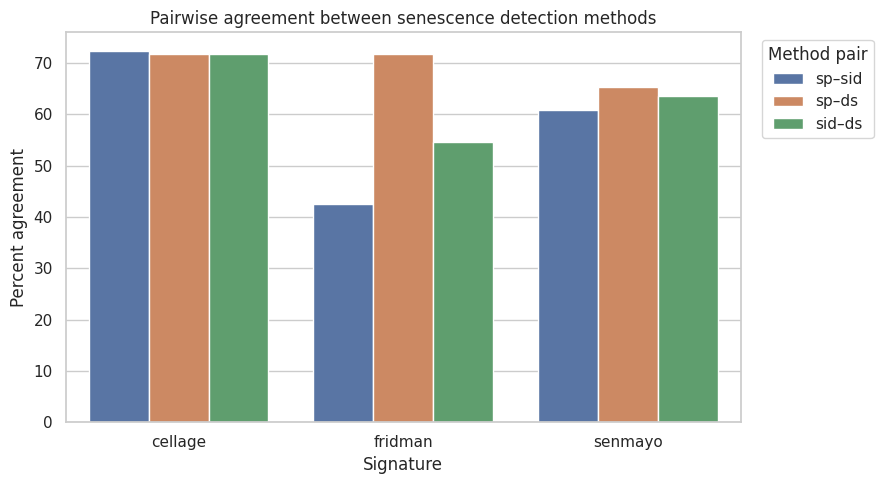

In [99]:
plot_pairwise_summary(
    pair_metrics_df,
    "percent_agreement",
    ylabel="Percent agreement",
    title="Pairwise agreement between senescence detection methods",
)

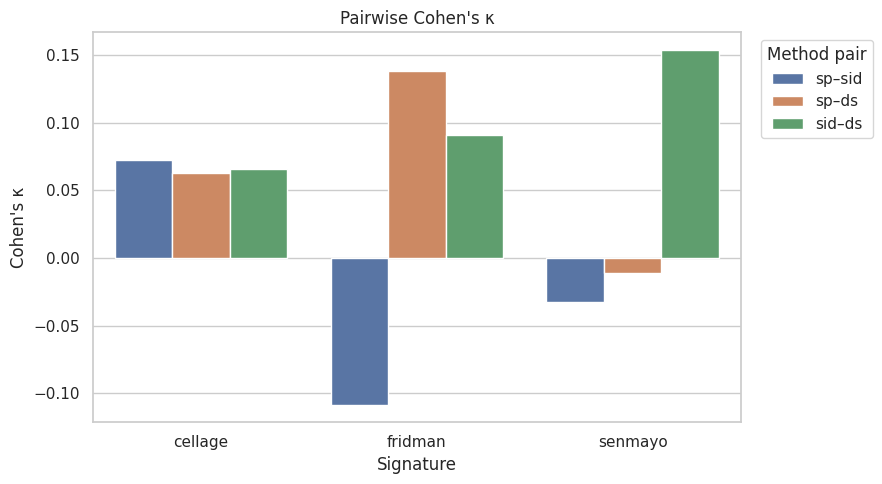

In [100]:
plot_pairwise_summary(
    pair_metrics_df, "cohen_kappa", ylabel="Cohen's κ", title="Pairwise Cohen's κ"
)

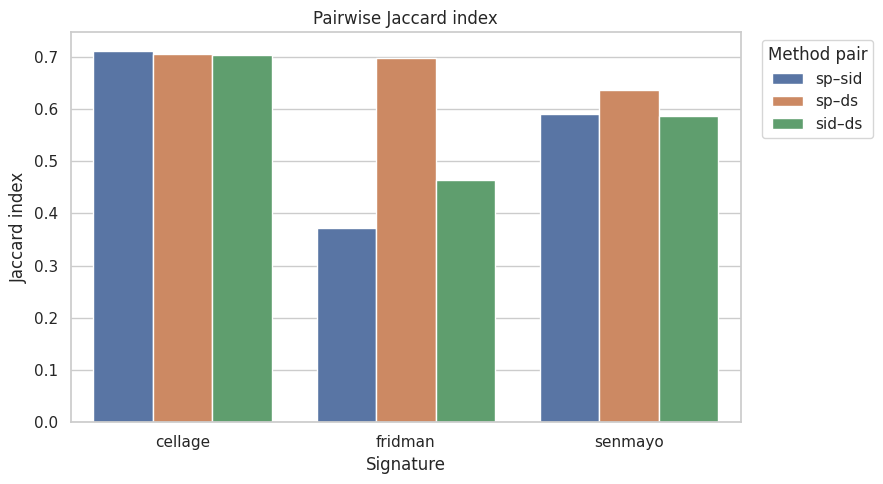

In [101]:
plot_pairwise_summary(
    pair_metrics_df,
    "jaccard_positive",
    ylabel="Jaccard index",
    title="Pairwise Jaccard index",
)

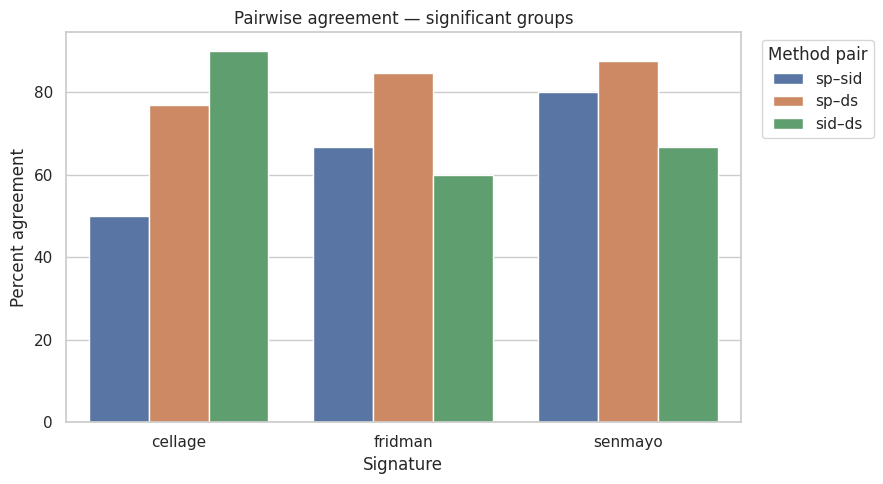

In [102]:
plot_pairwise_summary(
    pair_sig_metrics_df,
    "percent_agreement",
    ylabel="Percent agreement",
    title="Pairwise agreement — significant groups",
)

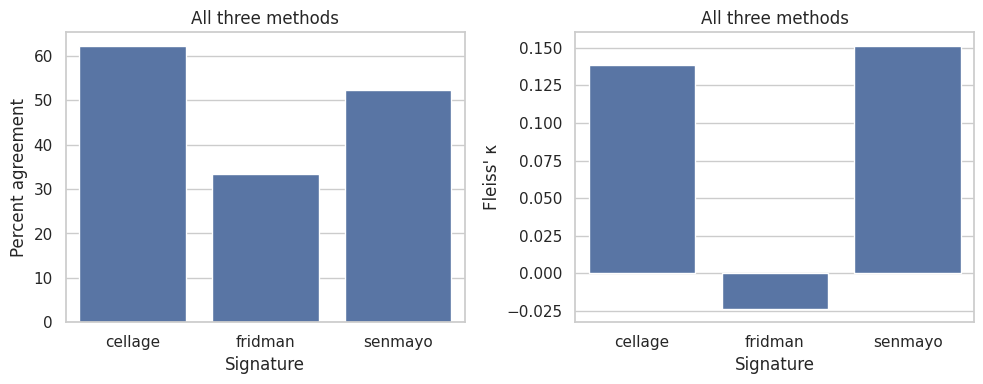

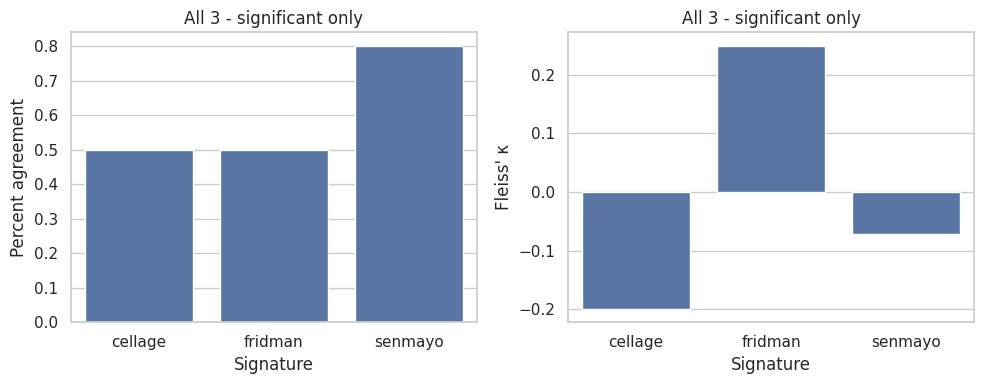

In [103]:
"""Общая визуализация для всех трёх методов (все + только значимые RBC)"""

for i, plot_df in enumerate([all3_metrics_df, all3_sig_metrics_df]):
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))

    sns.barplot(
        data=plot_df,
        x="signature",
        y="percent_agreement",
        ax=axes[0],
        errorbar=None,
    )
    title = "All three methods"
    if i == 1:
        title = "All 3 - significant only"
    axes[0].set_xlabel("Signature")
    axes[0].set_ylabel("Percent agreement")
    axes[0].set_title(title)

    sns.barplot(
        data=plot_df, x="signature", y="fleiss_kappa", ax=axes[1], errorbar=None
    )

    axes[1].set_xlabel("Signature")
    axes[1].set_ylabel("Fleiss' κ")
    axes[1].set_title(title)

    plt.tight_layout()
    plt.show()

**Визуализация agreement по группам (все RBC)**

In [ ]:
def plot_group_agreement(df, agreement_col, method_pair, title_suffix=""):

    signatures = df["signature"].dropna().unique()

    fig, axes = plt.subplots(
        1, len(signatures), figsize=(6 * len(signatures), 6), squeeze=False
    )

    axes = axes[0]

    for ax, signature in zip(axes, signatures):
        sub = df[df["signature"] == signature].copy()

        heatmap_df = sub.pivot(
            index="Tissue_global", columns="cell_type", values=agreement_col
        )

        sns.heatmap(
            heatmap_df,
            ax=ax,
            vmin=0,
            vmax=1,
            cmap="viridis",
            annot=True,
            fmt=".0f",
            cbar=False,
            linewidths=0.5,
        )

        ax.set_title(signature)
        ax.set_xlabel("Cell type")
        ax.set_ylabel("Tissue")

    fig.suptitle(f"{method_pair}: direction agreement {title_suffix}", y=1.02)

    plt.tight_layout()
    plt.show()

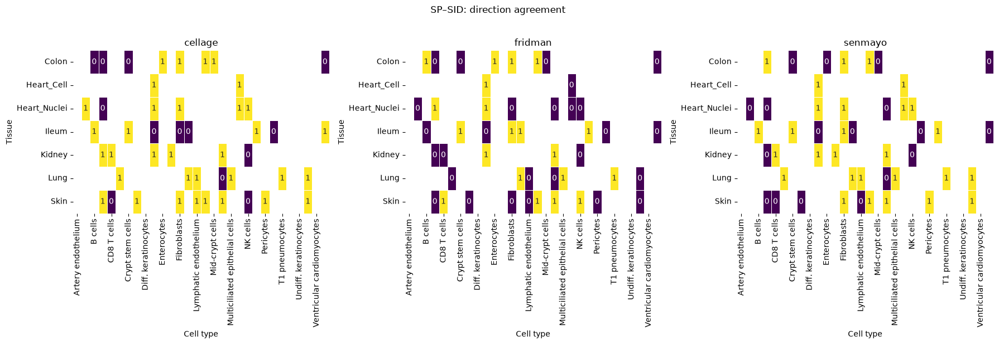

In [63]:
plot_group_agreement(agreement_df, "agreement_sp_sid", "SP–SID")

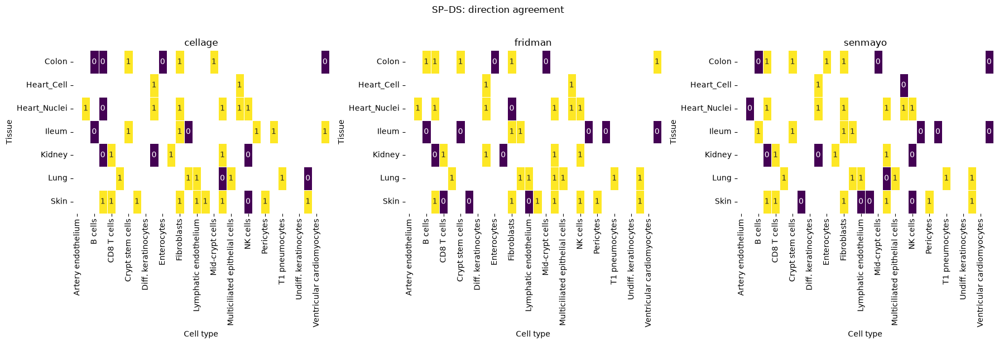

In [64]:
plot_group_agreement(agreement_df, "agreement_sp_ds", "SP–DS")

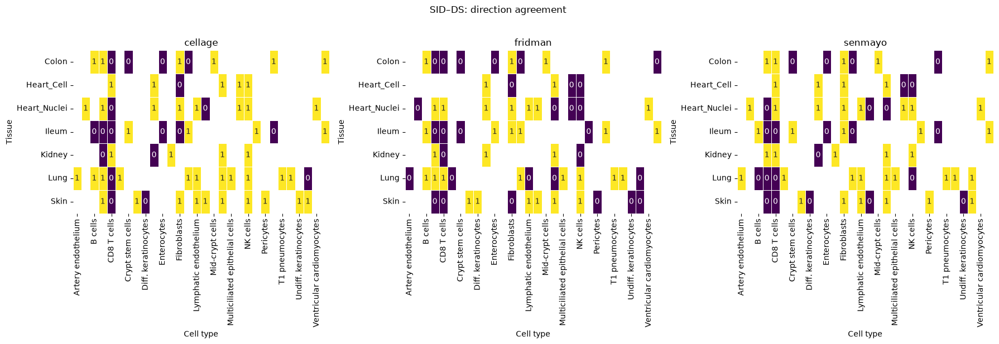

In [65]:
plot_group_agreement(agreement_df, "agreement_sid_ds", "SID–DS")

In [ ]:
agreement_df

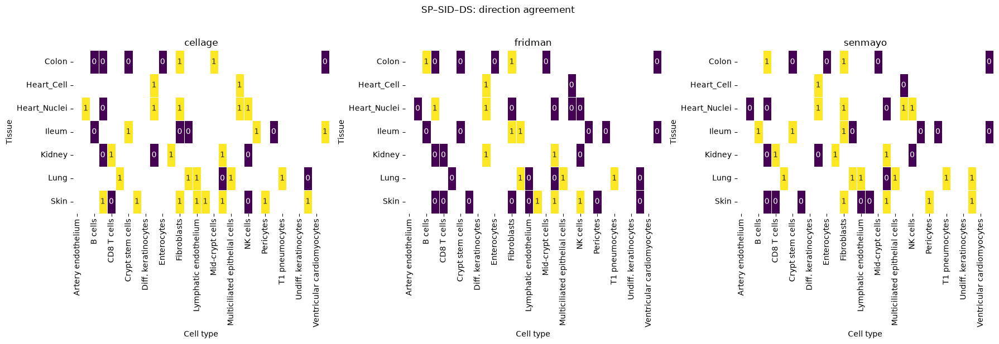

In [66]:
plot_group_agreement(agreement_df, "agreement_all3", "SP–SID–DS")

In [ ]:
# ПАРЫ МЕТОДОВ
method_pairs = [
    ("ds", "sp"),
    ("sp", "sid"),
    ("sid", "ds"),
]
agreement_columns = {
    ("ds", "sp"): "agreement_sp_ds",
    ("sp", "sid"): "agreement_sp_sid",
    ("sid", "ds"): "agreement_sid_ds",
}
pair_labels = [
    "DS – SP",
    "SP – SID",
    "SID – DS",
]
signature_labels = {
    "fridman": "f",
    "senmayo": "s",
    "cellage": "c",
}

# ПОРЯДОК СТРОК
row_order = (
    agreement_df[["Tissue_global", "cell_type"]]
    .drop_duplicates()
    .sort_values(["Tissue_global", "cell_type"])
    .reset_index(drop=True)
)
row_order["row_label"] = (
    row_order["Tissue_global"].astype(str) + " | " + row_order["cell_type"].astype(str)
)

# СОЗДАНИЕ ТРЁХ БЛОКОВ
blocks = []
for pair in method_pairs:
    agreement_col = agreement_columns[pair]
    block = (
        agreement_df.pivot_table(
            index=["Tissue_global", "cell_type"],
            columns="signature",
            values=agreement_col,
            aggfunc="first",
        )
        .reindex(pd.MultiIndex.from_frame(row_order[["Tissue_global", "cell_type"]]))
        .reindex(columns=sen_sigs)
    )
    blocks.append(block)

# ОБЪЕДИНЯЕМ БЛОКИ ПО ГОРИЗОНТАЛИ
heatmap_data = pd.concat(
    blocks,
    axis=1,
)

# ПОДПИСИ СТРОК
heatmap_data.index = row_order["row_label"]

# НАЗВАНИЯ КОЛОНОК
heatmap_data.columns = (
    [signature_labels[s] for s in sen_sigs]
    + [signature_labels[s] for s in sen_sigs]
    + [signature_labels[s] for s in sen_sigs]
)

# FIGURE
fig, ax = plt.subplots(
    figsize=(14, len(heatmap_data) * 0.23 + 2),
    dpi=300,
)

# HEATMAP
sns.heatmap(
    heatmap_data,
    ax=ax,
    annot=True,
    # fmt=".2f",
    vmin=0,
    vmax=1,
    cmap="viridis",
    linewidths=0,
    linecolor="white",
    cbar=False,
    mask=heatmap_data.isna(),
    annot_kws={
        "fontsize": 10,
    },
)
ax.grid(False)

# ПРОЧЕРКИ ДЛЯ ОТСУТСТВУЮЩИХ ЗНАЧЕНИЙ
for row_idx in range(heatmap_data.shape[0]):
    for col_idx in range(heatmap_data.shape[1]):
        if pd.isna(heatmap_data.iloc[row_idx, col_idx]):
            ax.text(
                col_idx + 0.5,
                row_idx + 0.5,
                "—",
                ha="center",
                va="center",
                fontsize=18,
                color="grey",
            )

# Y-AXIS
ax.set_yticklabels(
    ax.get_yticklabels(),
    fontsize=18,
    fontweight="semibold",
    rotation=0,
)
ax.set_ylabel("")

# X-AXIS
ax.set_xticks(np.arange(len(heatmap_data.columns)) + 0.5)
ax.set_xticklabels(
    heatmap_data.columns,
    fontsize=18,
    fontweight="semibold",
    rotation=0,
)
ax.set_xlabel("")

# ВЕРТИКАЛЬНЫЕ ГРАНИЦЫ МЕЖДУ ПАРАМИ
for x in [3, 6]:
    ax.axvline(
        x,
        color="black",
        linewidth=1.5,
    )

# ПОДПИСИ ПАР НАД ТРОЙКАМИ
for i, label in enumerate(pair_labels):
    center = i * 3 + 1.5
    ax.text(
        center,
        1.01,
        label,
        transform=ax.get_xaxis_transform(),
        ha="center",
        va="bottom",
        fontsize=20,
        fontweight="semibold",
    )

# ОФОРМЛЕНИЕ
sns.despine(
    ax=ax,
    left=False,
    bottom=False,
)

plt.tight_layout()
plt.show()

In [ ]:
# Словарь сравнений и колонки берем из вашего исходного кода
comparisons = {
    "DS – SP": "agreement_sp_ds",
    "SP – SID": "agreement_sp_sid",
    "SID – DS": "agreement_sid_ds",
    "ALL 3": "agreement_all3",
}

# Итерируемся напрямую по структуре вашего словаря
for comparison, column in comparisons.items():
    # Списки для сбора промежуточных значений по текущей группе методов
    sig_data = []

    # Собираем данные по каждой сигнатуре в рамках текущего сравнения
    for signature in sen_sigs:
        values = agreement_df.loc[agreement_df["signature"] == signature, column]

        n_0 = (values == 0).sum()
        n_1 = (values == 1).sum()

        sig_data.append({"signature": signature, "n_0": n_0, "n_1": n_1})

    # Считаем общие суммы (TOTAL) для всей группы сравнения методов
    total_0 = sum(d["n_0"] for d in sig_data)
    total_1 = sum(d["n_1"] for d in sig_data)

    # --- КРАСИВЫЙ ВЫВОД В КОНСОЛЬ ---
    print(f"\n{comparison}")
    print(f"TOTAL -> 0: {total_0}, 1: {total_1}")
    print("-" * 30)  # Разделительная черта

    # Выводим строки для каждой сигнатуры
    for d in sig_data:
        print(f"  {d['signature']:<10} 0: {d['n_0']:<3} 1: {d['n_1']}")



DS – SP
TOTAL -> 0: 42, 1: 96
------------------------------
  fridman    0: 13  1: 33
  senmayo    0: 16  1: 30
  cellage    0: 13  1: 33

SP – SID
TOTAL -> 0: 58, 1: 82
------------------------------
  fridman    0: 27  1: 20
  senmayo    0: 18  1: 28
  cellage    0: 13  1: 34

SID – DS
TOTAL -> 0: 73, 1: 126
------------------------------
  fridman    0: 30  1: 36
  senmayo    0: 24  1: 42
  cellage    0: 19  1: 48

ALL 3
TOTAL -> 0: 68, 1: 66
------------------------------
  fridman    0: 30  1: 15
  senmayo    0: 21  1: 23
  cellage    0: 17  1: 28


**Визуализация agreement по группам (только стат.значимые RBC)**

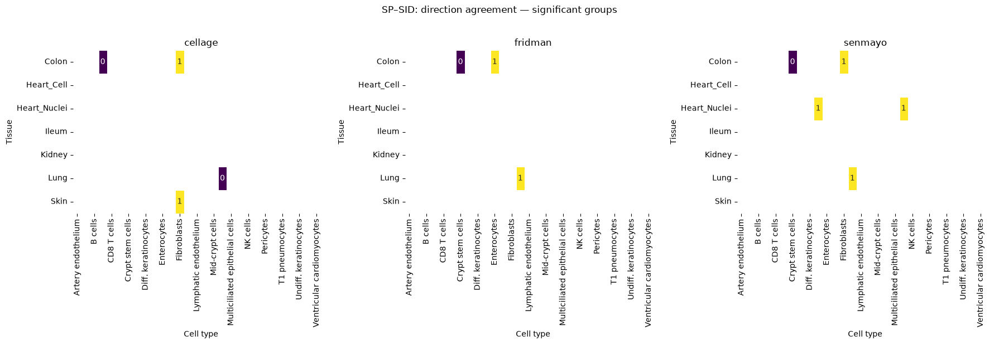

In [67]:
plot_group_agreement(
    agreement_sig_df, "agreement_sp_sid", "SP–SID", title_suffix="— significant groups"
)

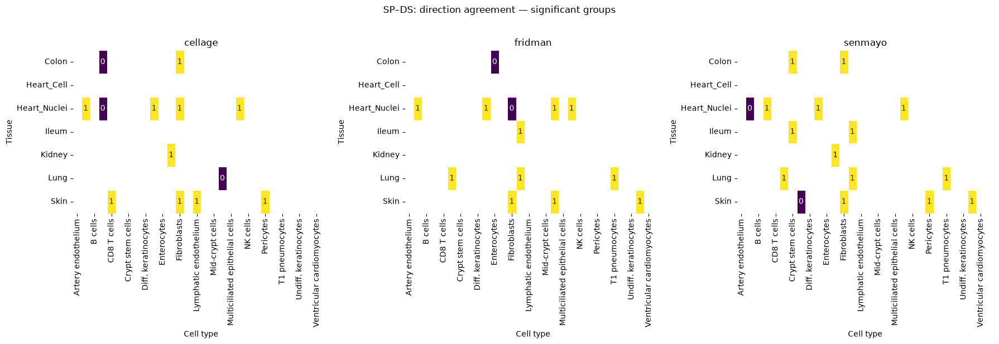

In [68]:
plot_group_agreement(
    agreement_sig_df, "agreement_sp_ds", "SP–DS", title_suffix="— significant groups"
)

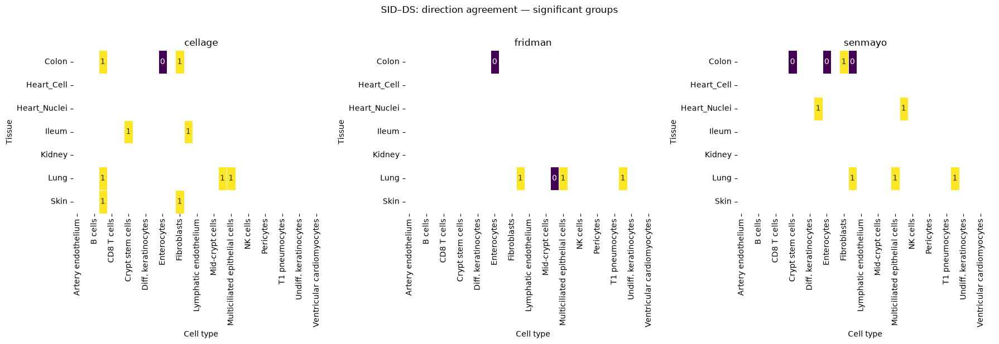

In [69]:
plot_group_agreement(
    agreement_sig_df, "agreement_sid_ds", "SID–DS", title_suffix="— significant groups"
)